# Tomopy Reconstruction of the XMCD signal 
[Tomopy Documentation](https://tomopy.readthedocs.io/en/stable/)
## Purpose
This notebook reconstructs the XMCD signal for the tilt series of one in plane (Γ) rotations. It takes the outputs of `Gamma_Alpha_Alignment.ipynb`.

## Workflow 
1. **Rotate COR by 90 deg** — shift COR to the center of the image and rotate by 90 deg so that the tilt geometry matches the tomopy input
2. **Identify shift in COR** — Based on the x,y coordinates of the COR fit in Gamma_Alpha_alignment, identify the needed shift in the COR to get a non-distorted reconstruction.
3. **Shift the zero position and the linear motor angle**-- adjust for any errors in the zero position by shifting the angle array by some amount
4. **Reconstruct with mask** -- mask applied to free reconstruction and then mask applied as an iterative step during reconstruction
5. **Take line cuts and plot hyperbolic tangent wall**-- compare fit domain wall width and position between reconstructions 


## Dependencies
All shared functions live in `Reconstruction_Functions.py` (same directory) and are accessed
as `reconstruct.function_name()`.import Reconstruction_Functions as reconstruct

---
## Step 1 — Imports

In [4]:
import tomopy
import os
import numpy as np
from skimage.io import imread, imsave
import matplotlib.pyplot as plt
from scipy.ndimage import rotate, shift
#import dxchange
import time

from skimage.registration import phase_cross_correlation
from skimage.transform import warp_polar
from numpy.fft import fft2, fftshift
import tifffile
from scipy.optimize import curve_fit, fsolve
from skimage.measure import profile_line

# All shared functions imported from Functions.py as 'register'
import Reconstruction_Functions as reconstruct


---
## Step 2 — User Configuration

**Edit this cell for every new dataset / Gamma.**
All parameters that vary between samples, Gammas, or processing runs are
defined here and propagated automatically.

In [9]:
sample = '665'
Gamma = 'Gammaneg45'
data_dir =  f"/homes/emma/notebooks/RawData/{sample}/{Gamma}/"


if sample == '665': 
    center1 = 257
    date = '_3AUG25_check_saturation_n50'
    date1 = '_5AUG25_check_saturation_n50'    
    modifier = 'normalize_by_kmeans'

    yo_0 = 257
    xo_0 = 276

    if Gamma == 'Gamma0':
        print('665, gamma0')
        
        
        # data_0 = os.path.join(data_dir,'Gamma_alpha_aligned_XMCD_3AUG25_check_saturation_n50_sliced_forDinesh_nan.tiff')
        # angles = os.path.join(data_dir,'sliced_angles_3AUG25_check_saturation_n50_forDinesh_nan.txt') ## original normal shift
        # yo_0 = 250
        # xo_0 = 276
        #data_0 = os.path.join(PATH,'center_alpha_aligned_XMCD_siny_cosx_5AUG25_check_saturation_n50.tiff')
        #angles = os.path.join(PATH,'angles_shifted_3AUG25_check_saturation_n50.txt')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')
        

        k0 = 55
        shift_angle = -2.5
    
    elif Gamma == 'Gammaneg45': 
        print('665, gammaneg45')
        
        # data_0 = os.path.join(data_dir,'Gamma_alpha_aligned_XMCD_5AUG25_check_saturation_n50_sliced_forDinesh_nan.tiff')
        # angles = os.path.join(data_dir,'sliced_angles_5AUG25_check_saturation_n50.txt')
        # yo_0 = 250
        # xo_0 = 276
        
        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')
        
        #centroid_x_45 = (np.loadtxt(os.path.join(PATH, 'x_aligned_centroid_shift_5AUG25_check_saturation_n50_select_forDinesh_nan.txt')))
        #centroid_y_45 = (np.loadtxt(os.path.join(PATH, 'y_aligned_centroid_shift_5AUG25_check_saturation_n50_select_forDinesh_nan.txt')))
        
        k0 = 55
        shift_angle = -1

elif sample == '105': 
    center1 = 257
    date = '_17NOV25_auto_select_scans_fullrange'
    date1 = '_19NOV25_select_fullrange'
    yo_0 = 293 
    xo_0 = 271

    if Gamma == 'Gamma0':
        # PROJECTIONS = os.path.join(PATH,'center_alpha_aligned_CC_sin_17NOV25_auto_select_scans_fullrange_skipped.tiff')
        # ANGLES = os.path.join(PATH,'angles_negpol_17NOV25_auto_select_scans_fullrange.txt')
        # data_0 = os.path.join(data_dir,'center_alpha_aligned_XMCD_sin_17NOV25_auto_select_scans_fullrange_skipped.tiff')
        # angles = os.path.join(data_dir,'angles_shifted_17NOV25_auto_select_scans_fullrange.txt')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')
        
        k0 = 55
        shift_angle = 6 #2.4
        
    elif Gamma == 'Gamma45': 
        # data_0 = os.path.join(data_dir,'center_alpha_aligned_XMCD_sin_19NOV25_select_fullrange.tiff')
        # angles = os.path.join(data_dir,'angles_negpol_19NOV25_select_fullrange.txt')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')

        k0 = 25
        shift_angle = -2

    # PROJECTIONS = os.path.join(PATH,'center_alpha_aligned_CC_sin_19NOV25_select_fullrange.tiff')
    # #ANGLES = os.path.join(PATH,'select_angles_5AUG25_check_saturation_n50_forDinesh_nan.txt')
    
    # ### Using the angles from Gamma == 0 here ### 
    # ANGLES = os.path.join(PATH,'angles_negpol_19NOV25_select_fullrange.txt')

elif sample == '452': 
    modifier = 'normalize_by_kmeans'
    date = '_16MAR26_og_ptycho'
    date1 = '_1APR26_recon_ptycho'
    date2 = '_21MAR26_og_ptycho'
    center1 = 375
    yo_0 = 388
    xo_0 = 406
    
    if Gamma == 'Gamma90':
        print('452, gamma90')
        
        # data_0 = os.path.join(data_dir,'OD_XMCD_stack_16MAR26_og_ptycho_Gamma90_all_scans_failed_psd.tiff')
        # #data_0 = os.path.join(PATH,'center_alpha_aligned_XMCD_siny_cosx_5AUG25_check_saturation_n50.tiff')
        # angles = os.path.join(data_dir,'angles_shifted_16MAR26_og_ptycho_Gamma90_all_scans_failed_psd.txt') ## original normal shift
        # #angles = os.path.join(PATH,'angles_shifted_3AUG25_check_saturation_n50.txt')
        yo_0 = 423
        xo_0 = 436

        data_0 = os.path.join(data_dir,'center_alpha_aligned_XMCD_16MAR26_og_ptycho_Gamma90_normalize_by_kmeans.tiff')
        angles = os.path.join(data_dir,'angles_shifted_16MAR26_og_ptycho_Gamma90_normalize_by_kmeans.txt')

        # centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        # centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        # data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        # angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')

        k0 = 55
        shift_angle = -2.5

    if Gamma == 'Gamma0':
        print('452, gamma90')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')

        k0 = 55
        shift_angle = -2.5

    if Gamma == 'Gamma45':
        print('452, gamma90')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date2}_{Gamma}_{modifier}.txt')

        k0 = 55
        shift_angle = 2 #-2.5


elif sample == '270': 
    date = '_29APR26_og_ptycho'
    date1 = '_29APR26_og_ptycho_light_on'
    date2 = '_29APR26_og_ptycho_light_on'
    modifier = 'bsub_kmeans_rot_log10'
    center1 = 257
    yo_0 = 263
    xo_0 = 240
    
    if Gamma == 'Gamma90':
        print('452, gamma90')
        
        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')

        k0 = 11
        shift_angle = 4.5

    if Gamma == 'Gamma0':
        print('452, gamma0')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date1}_{Gamma}_{modifier}.txt')

        k0 = 24
        shift_angle = -1

    if Gamma == 'Gamma45':
        print('452, gamma45')

        centroid_x_0 =(np.loadtxt(os.path.join(data_dir, f"Gamma_x_centroid_aligned{date1}_{Gamma}_{modifier}.txt")))
        centroid_y_0 = (np.loadtxt(os.path.join(data_dir, f'Gamma_y_centroid_aligned{date1}_{Gamma}_{modifier}.txt')))
        data_0 = os.path.join(data_dir,f"Gamma_alpha_aligned_XMCD{date1}_{Gamma}_{modifier}.tiff")
        angles = os.path.join(data_dir,f'angles_shifted{date}_{Gamma}_{modifier}.txt')

        k0 = 6
        shift_angle = 6


# print(type(centroid_y_45))
proj_0 = imread(data_0)
print(proj_0.shape)
proj_0 = proj_0.astype(np.float32)
proj_0[np.isnan(proj_0)] = 0
proj_0[np.isinf(proj_0)] = 0

f = open(angles, 'r')
ang = []
for item in f:
    ang.append(float(item)) 
f.close()
ang = np.array(ang) + shift_angle
ang_deg = ang
ang = np.array(ang)*np.pi/180.
print(f'angle shape = {ang.shape}')
print(np.min(ang)) 
print(np.max(ang))
# k0 = 55
print(ang_deg[k0])

665, gammaneg45
(117, 514, 514)
angle shape = (117,)
-1.279031017620893
0.9724411280813139
-12.1208878


# shift image center to the center of rotation determined in Gamma_alignment_final 
## Rotate the projection 90 degrees around this point so that the axis of rotation is vertical

(117, 514, 514)


Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)Error.  nthreads must be a positive integer

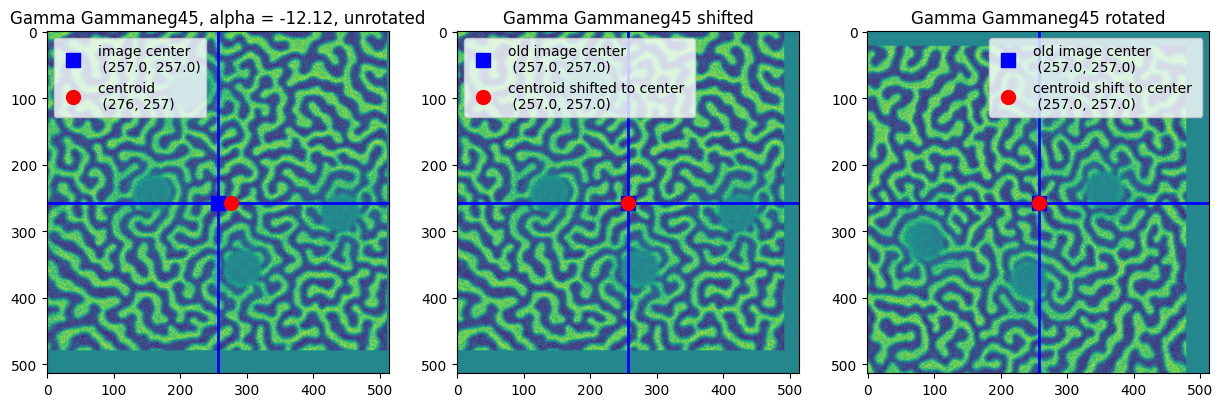

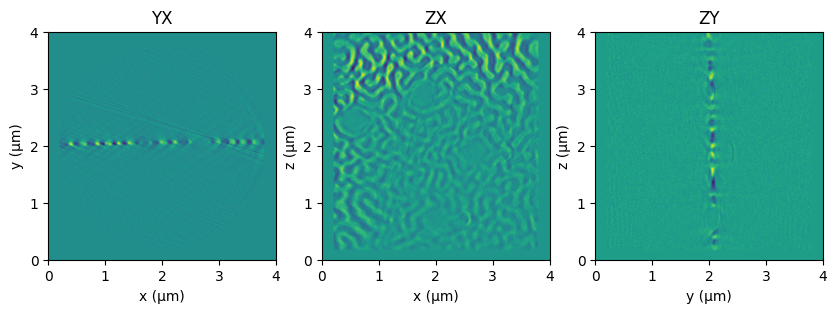

In [8]:
vertical_angle = 90
k = k0

rotated_0_0 = reconstruct.rotate_about_COR(proj_0[k], vertical_angle, yo_0, xo_0, ang_deg[k], sample, Gamma, order=3, plot = True)

rotated_0 = [ ]
for i in range(proj_0.shape[0]):
    rotated = reconstruct.rotate_about_COR(proj_0[i], vertical_angle, yo_0, xo_0, ang_deg[i],  sample, Gamma, order=3, plot = False)
    rotated_0.append(rotated)
rotated_0 = np.array(rotated_0)
print(rotated_0.shape)

### quick tomography check 
center2 = center1 +13
recon_0 = tomopy.recon(rotated_0, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
recon_0 = tomopy.circ_mask(recon_0, axis=0, ratio=0.90) 
## Plot and check centering
k = center1
reconstruct.plot_crosssections (k, recon_0)

# Manual shift to improve center
- propogate into the if else tree below

shift = -5 for rotation center = 252
shift = 0 for rotation center = 257


Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)Error.  nthreads must be a positive integerError.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)Error.  nthreads must be a positive integerError.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)Error.  nthreads must be a positive integer

shift = 5 for rotation center = 262


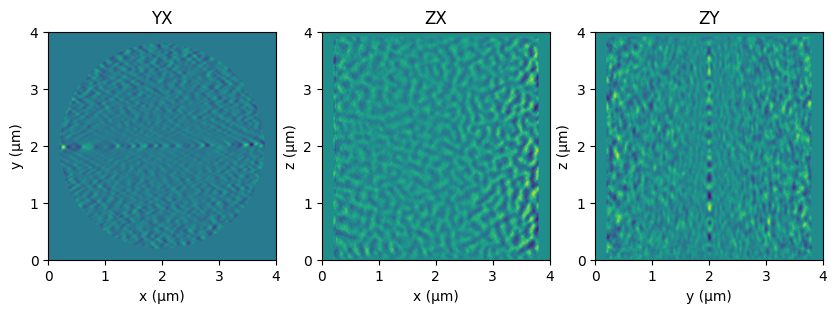

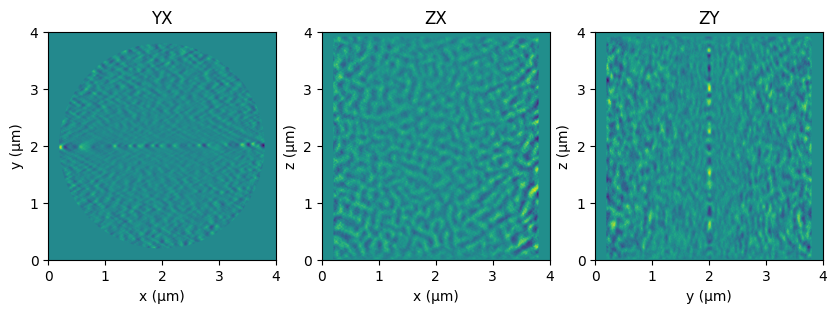

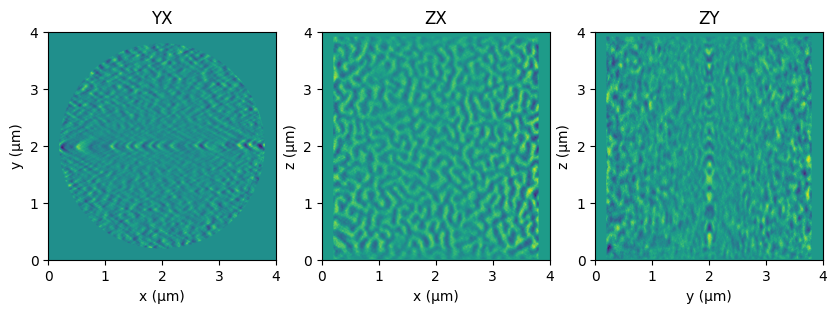

In [11]:
shifts = [-5,0,5] 
for i in shifts: 

    ## Reconstruction with full image 
    ## Gamma = 0
    center = center1 + i
    print(f'shift = {i} for rotation center = {center}')
    #print(f'rotation center = {center}')
    recon_1 = tomopy.recon(rotated_0, ang, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon_1 = tomopy.circ_mask(recon_1, axis=0, ratio=0.90)

    k = center1
    reconstruct.plot_crosssections (k, recon_1)

    


## find film center

257
250
251
252
253
254


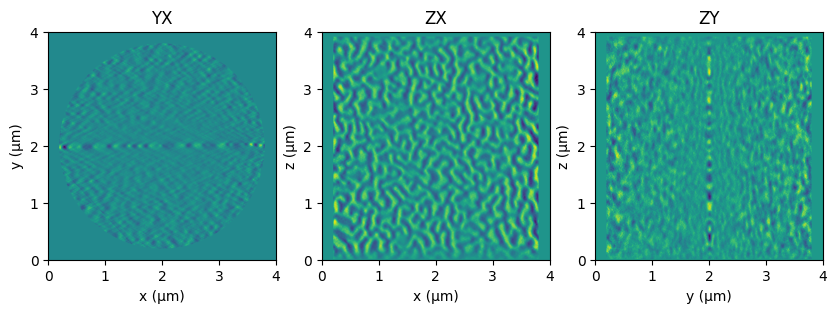

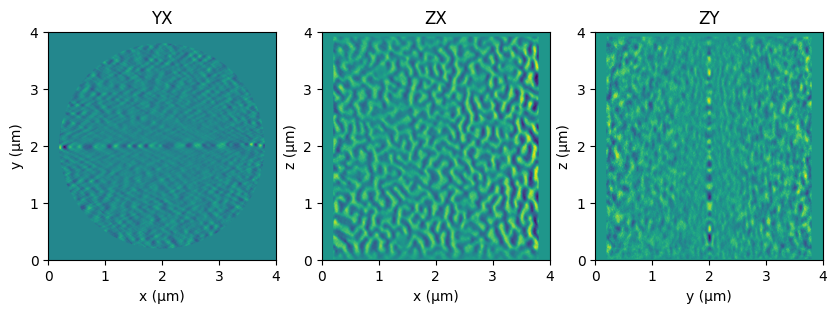

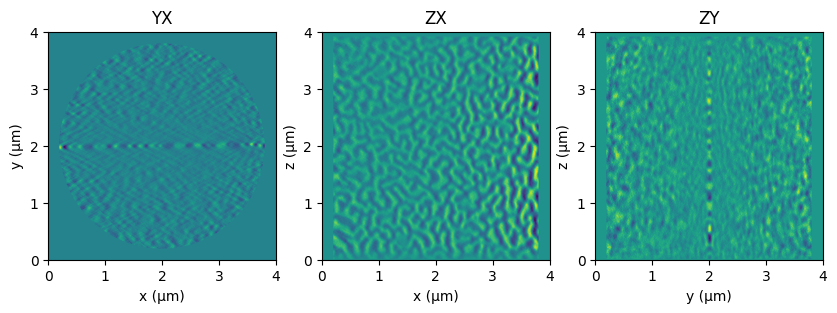

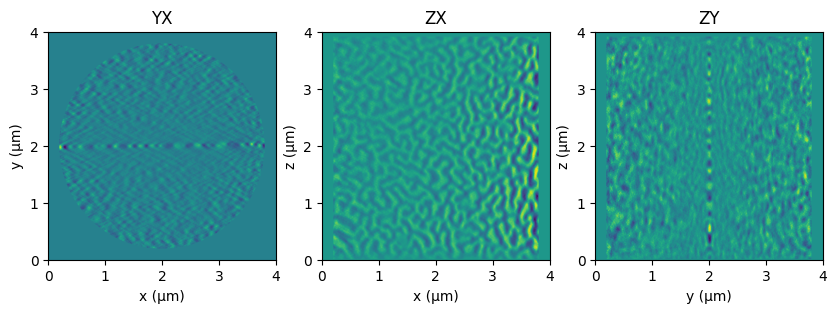

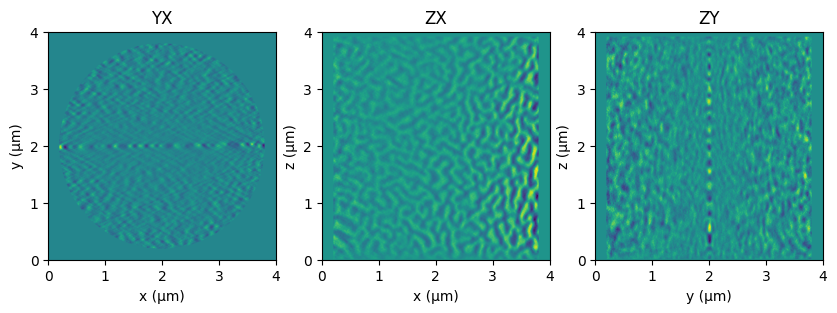

In [15]:
# center2 = center1 + 13
# recon_0 = tomopy.recon(rotated_0, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
# recon_0 = tomopy.circ_mask(recon_0, axis=0, ratio=0.90)
print(center1)
shift_list = [-7,-6, -5, -4, -3] #452 shift = 7

for s in shift_list: 
    k = center1 + s
    print(k)
    reconstruct.plot_crosssections (k, recon_0)


# Other tests

In [ ]:
## shift image center by 13 based on images above!!!!!
if sample == '665': 
    shifts = 13
elif sample == '105': 
    if Gamma == 'Gamma0': 
        shifts = 53
    elif Gamma == 'Gammaneg45': 
        shifts = 39
print(shifts)
center1 = 257
center2 = center1+shifts

recon_shift = tomopy.recon(rotated_0, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
recon_shift = tomopy.circ_mask(recon_shift, axis=0, ratio=0.90) 

k = 260
reconstruct.plot_crosssections (k, recon_shift)

k = 264
reconstruct.plot_crosssections (k, recon_shift)

k = 269
reconstruct.plot_crosssections (k, recon_shift)

In [ ]:
og = 0.88976

Gamma = 0
center1 = 257 #257 due to shifting COR to the center pixel and rotating around that
if Gamma == 0: 
    scale = [0.985, 0.99, 0.995, 1] 
    for i in scale: 

        ## Reconstruction with full image 
        ## Gamma = 0
       
        print(f'scale = {og*i}')
        #print(f'rotation center = {center}')
        recon_0 = tomopy.recon(rotated_0, ang*i, center=center2, algorithm='gridrec', sinogram_order=False) ### 
        recon_0 = tomopy.circ_mask(recon_0, axis=0, ratio=0.90)

        k = 263
        plot_crosssections (k, recon_0)
        
    

In [ ]:
save = False
if save == True: 
    print('saved')
    tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_shifted13_2deg.tiff", recon_shift.astype(np.float32))
else: 
    print('no save')

## KP's 1/4 test

In [ ]:
def concavity_test(proj, ang, yo_0, xo_0, center1, center2, vertical_angle, shift_list, sample, Gamma): 

    # 1. Need to rotate the projection
    for i in vertical_angle: 
        rotated_test = [ ]
        for j in range(proj.shape[0]):
            rotated_i = reconstruct.rotate_about_COR(proj[j], i, yo_0, xo_0, ang[j], sample, Gamma, order=3, plot = False)
            rotated_test.append(rotated_i)
            
        rotated_test = np.array(rotated_test)
        
    # 2. reconstruct rotated stack
        recon = tomopy.recon(rotated_test, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
        recon = tomopy.circ_mask(recon, axis=0, ratio=0.90)

    # 3. Plot each slice in the shift list
        # --- Extract Nx, Ny ---
        Nz, Ny, Nx = recon.shape 
    
        # --- Define physical extent in μm ---
        FOV_x = 4.0  # μm
        FOV_y = 4.0  # μm
    
        extent = [0, FOV_x, 0, FOV_y]  # [xmin, xmax, ymin, ymax] in μm
    
        # Tick positions every 1 μm
        ticks_um = np.arange(0, (FOV_x+0.1), 1.0)
        

        for s in shift_list: 
            k = center1 + s
        
            # --- Plot ---
            fig = plt.figure(figsize=(10, 6))
        
            ax1 = fig.add_subplot(1, 3, 1)
            ax1.imshow(recon[k,:,:], extent = extent, origin = 'lower')
            ax1.set_title(f'YX')
            ax1.set_ylabel("y (μm)")
            ax1.set_yticks(ticks_um)
            ax1.set_xlabel("x (μm)")
            ax1.set_xticks(ticks_um)
            ax1.set_title(f"{sample}, {Gamma} @ rot = {i} deg. and slice = {s}")
            
            ax2 = fig.add_subplot(1, 3, 2)
            ax2.imshow(recon[:,k,:], extent = extent, origin = 'lower')
            ax2.set_title('ZX')
            ax2.set_ylabel("z (μm)")
            ax2.set_yticks(ticks_um)
            ax2.set_xlabel("x (μm)")
            ax2.set_xticks(ticks_um)
            
            ax3 = fig.add_subplot(1, 3, 3)
            ax3.imshow(recon[:,:,k], extent = extent, origin = 'lower')
            ax3.set_title('ZY')
            ax3.set_ylabel("z (μm)")
            ax3.set_yticks(ticks_um)
            ax3.set_xlabel("y (μm)")
            ax3.set_xticks(ticks_um)

            
        

## Change concavity 

In [ ]:
## we think 13 is a good cor. So, move up and down the film to observe how the concavity changes for each Gamma rotation 
vertical_angle = [ 89.5, 90, 92]
center2 = center1+13
shift_list = [ -1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9] 

concavity_test(proj_0, ang, yo_0, xo_0, center1, center2, vertical_angle, shift_list, sample, Gamma)

In [ ]:
## we think 13 is a good cor. So, move up and down the film to observe how the concavity changes for each Gamma rotation 
vertical_angle = [87, 88, 89, 89.5, 90, 90.5, 91, 92, 93]
center2 = center1+13
shift_list = [-5, -4, -3, -2, -1, 0, 1, 2, 3, 4, 5] 

concavity_test(proj_0, ang, yo_0, xo_0, center1, center2, vertical_angle, shift_list, sample, Gamma)


In [ ]:
#### Try shifting in plane rotation so ZY is straight 
# vertical_angle = [87, 88, 89, 90, 91, 92, 93]
# vertical_angle = [75, 85, 90, 100, 115]
vertical_angle = [87, 90, 92]

shifts = [13]
#vertical_angle = [90]
k = k0

# ## shift image center by 13 based on images above!!!!!
# if sample == '665': 
#     shifts = 13
# elif sample == '105': 
#     if Gamma == 'Gamma0': 
#         shifts = 53
#     elif Gamma == 'Gammaneg45': 
#         shifts = 39
# print(shifts)

center1 = 257 #257 due to shifting COR to the center pixel and rotating around that
#center2 = center1+shifts

for i in vertical_angle: 
    for k in shifts:
        center2 = center1+k
        print('######################################################')
        print(f'vertical angle = {i} for rotation shift = {k}')

        rotated_test = [ ]
        for j in range(proj_0.shape[0]):
            rotated_i = rotate_about_COR(proj_0[j], i, yo_0, xo_0, order=3, plot = False)
            rotated_test.append(rotated_i)
            
        rotated_test = np.array(rotated_test)
        
        print(rotated_test.shape)
        
        #print(f'rotation center = {center}')
        recon_k0 = tomopy.recon(rotated_test, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
        recon_k0 = tomopy.circ_mask(recon_k0, axis=0, ratio=0.90)

    # k = 260
    # plot_crosssections (k, recon_k0)

        k = 264
        plot_crosssections (k, recon_k0)

    # k = 269
    # plot_crosssections (k, recon_k0)
    
    print('######################################################')

In [ ]:
#### Try shifting in plane rotation so ZY is straight 
# vertical_angle = [87, 88, 89, 90, 91, 92, 93]
# vertical_angle = [75, 85, 90, 100, 115]
vertical_angle = [89, 89.5, 89.75, 90, 90.25, 90.5, 91]
shifts = [13]
#vertical_angle = [90]
k = k0

# ## shift image center by 13 based on images above!!!!!
# if sample == '665': 
#     shifts = 13
# elif sample == '105': 
#     if Gamma == 'Gamma0': 
#         shifts = 53
#     elif Gamma == 'Gammaneg45': 
#         shifts = 39
# print(shifts)

center1 = 257 #257 due to shifting COR to the center pixel and rotating around that
#center2 = center1+shifts

for i in vertical_angle: 
    for k in shifts:
        center2 = center1+k
        print('######################################################')
        print(f'vertical angle = {i} for rotation shift = {k}')

        rotated_test = [ ]
        for j in range(proj_0.shape[0]):
            rotated_i = rotate_about_COR(proj_0[j], i, yo_0, xo_0, order=3, plot = False)
            rotated_test.append(rotated_i)
            
        rotated_test = np.array(rotated_test)
        
        print(rotated_test.shape)
        
        #print(f'rotation center = {center}')
        recon_k0 = tomopy.recon(rotated_test, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
        recon_k0 = tomopy.circ_mask(recon_k0, axis=0, ratio=0.90)

    # k = 260
    # plot_crosssections (k, recon_k0)

        k = 264
        plot_crosssections (k, recon_k0)

    # k = 269
    # plot_crosssections (k, recon_k0)
    
    print('######################################################')

In [ ]:
#### Try shifting in plane rotation so ZY is straight 
# vertical_angle = [87, 88, 89, 90, 91, 92, 93]
# vertical_angle = [75, 85, 90, 100, 115]
vertical_angle = [89, 89.5, 89.75, 90, 90.25, 90.5, 91]
shifts = [5,15,25]
#vertical_angle = [90]
k = k0

# ## shift image center by 13 based on images above!!!!!
# if sample == '665': 
#     shifts = 13
# elif sample == '105': 
#     if Gamma == 'Gamma0': 
#         shifts = 53
#     elif Gamma == 'Gammaneg45': 
#         shifts = 39
# print(shifts)

center1 = 257 #257 due to shifting COR to the center pixel and rotating around that
#center2 = center1+shifts

for i in vertical_angle: 
    for k in shifts:
        center2 = center1+k
        print('######################################################')
        print(f'vertical angle = {i} for rotation shift = {k}')

        rotated_test = [ ]
        for j in range(proj_0.shape[0]):
            rotated_i = rotate_about_COR(proj_0[j], i, yo_0, xo_0, order=3, plot = False)
            rotated_test.append(rotated_i)
            
        rotated_test = np.array(rotated_test)
        
        print(rotated_test.shape)
        
        #print(f'rotation center = {center}')
        recon_k0 = tomopy.recon(rotated_test, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
        recon_k0 = tomopy.circ_mask(recon_k0, axis=0, ratio=0.90)

    # k = 260
    # plot_crosssections (k, recon_k0)

        k = 264
        plot_crosssections (k, recon_k0)

    # k = 269
    # plot_crosssections (k, recon_k0)
    
    print('######################################################')


In [ ]:
save = False
if save == True: 
    print('saved')
    tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_noshift.tiff", recon_0.astype(np.float32))
else: 
    print('no save')

# Mask for thickness

270
Gamma45


Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (64)Error.  nthreads must be a positive integer

Film thickness : 7 voxels  (54 nm)
Masked Y rows  : 245 → 251  (out of 500 total rows)


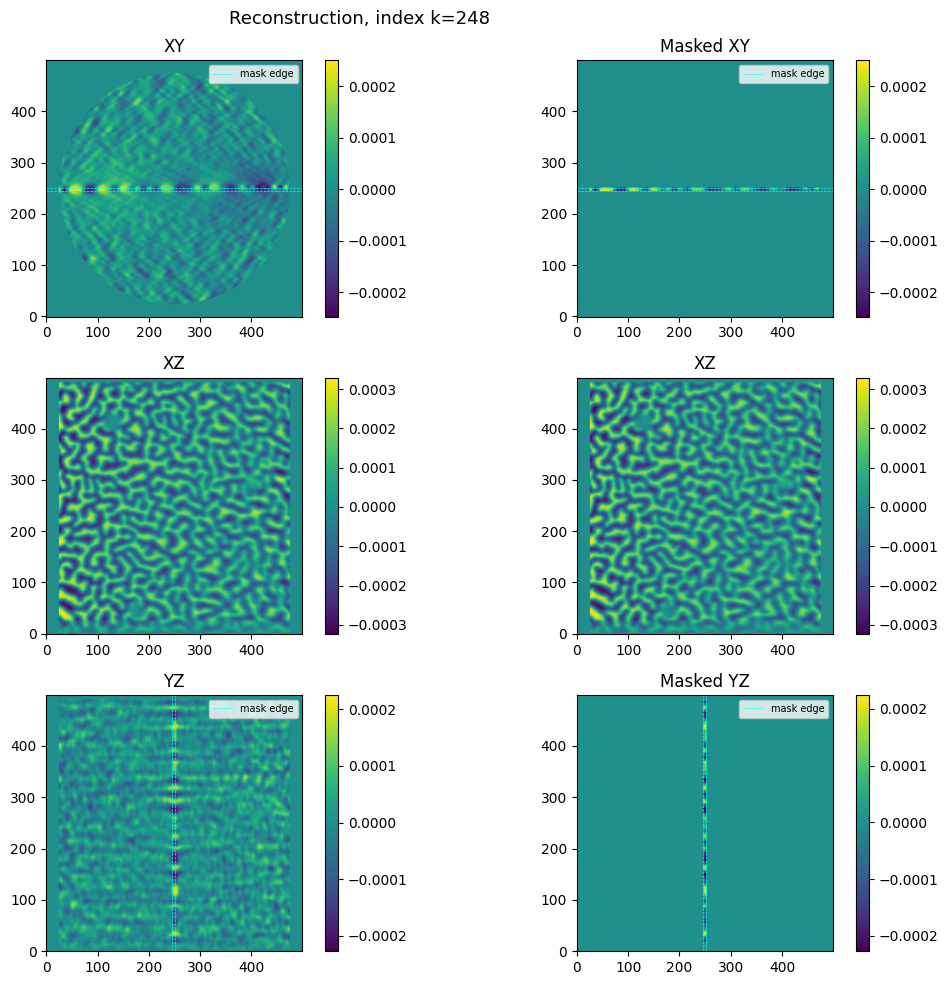

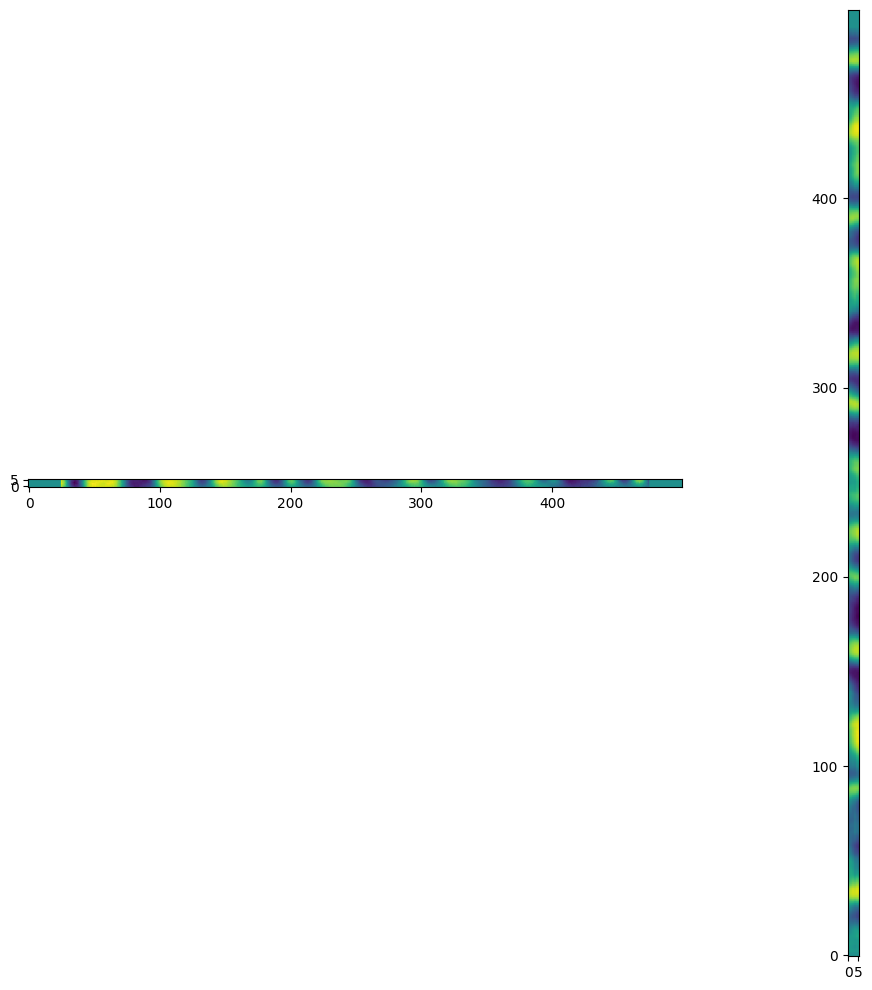

In [45]:

# ──────────────────────────────────────────────
# 0.  Recon parameters 
# ──────────────────────────────────────────────
if sample == '665':
    if Gamma == 'Gammaneg45':
        center2 = center1 + 15 #13
        film_thickness_nm = 66 #51
        s = -8 #10
    elif Gamma == 'Gamma0':
        center2 = center1 + 13 #15 
        film_thickness_nm = 51
        s = 7

elif sample == '105': 
    if Gamma == 'Gamma45':
        center2 = center1 + 11 #13
        film_thickness_nm = 45
        s = -15 #10
    elif Gamma == 'Gamma0':
        center2 = center1 + 7 
        film_thickness_nm = 45
        s = -15 #-8 #10
    

elif sample == '452': 
    center2 = center1 + 15 # 27
    film_thickness_nm = 33
    s = 1

elif sample == '270': 
    if Gamma == 'Gamma0':
        center2 = center1 + 0 # 27
        film_thickness_nm = 54
        s = -7
    elif Gamma == 'Gamma90':
        center2 = center1 + 0 # 27
        film_thickness_nm = 54
        s = -7
    elif Gamma == 'Gamma45':
        center2 = center1 + 0 # 27
        film_thickness_nm = 54 #54
        s = -9


print(sample)
print(Gamma)
# ──────────────────────────────────────────────
# 1.  FREE RECONSTRUCTION 
# ──────────────────────────────────────────────
recon_sirt = tomopy.recon(
    rotated_0, ang,
    center=center2,
    algorithm='sirt', 
    sinogram_order=False
)
recon_sirt = tomopy.circ_mask(recon_sirt, axis=0, ratio=0.90)


# ──────────────────────────────────────────────
# 2.  Mask physical thickness
# ──────────────────────────────────────────────
pixel_size_nm   = 8         # voxel size in nm  =
film_thickness_voxels = int(np.round(film_thickness_nm / pixel_size_nm))

film_center_y = center1 + s           
# ───────────────────────────────────────────────

mask, y_lo, y_hi = reconstruct.make_slab_mask(recon_sirt, film_thickness_voxels, film_center_y)
recon_masked = recon_sirt * mask

print(f"Film thickness : {film_thickness_voxels} voxels  "
      f"({film_thickness_nm:.0f} nm)")
print(f"Masked Y rows  : {y_lo} → {y_hi}  "
      f"(out of {recon_sirt.shape[1]} total rows)")

# ──────────────────────────────────────────────
# 3.  CROSS-SECTION PLOTS  (free vs masked)
# ──────────────────────────────────────────────

reconstruct.plot_crosssections_compare(film_center_y, recon_sirt, recon_masked, y_lo, y_hi)



## Linecuts

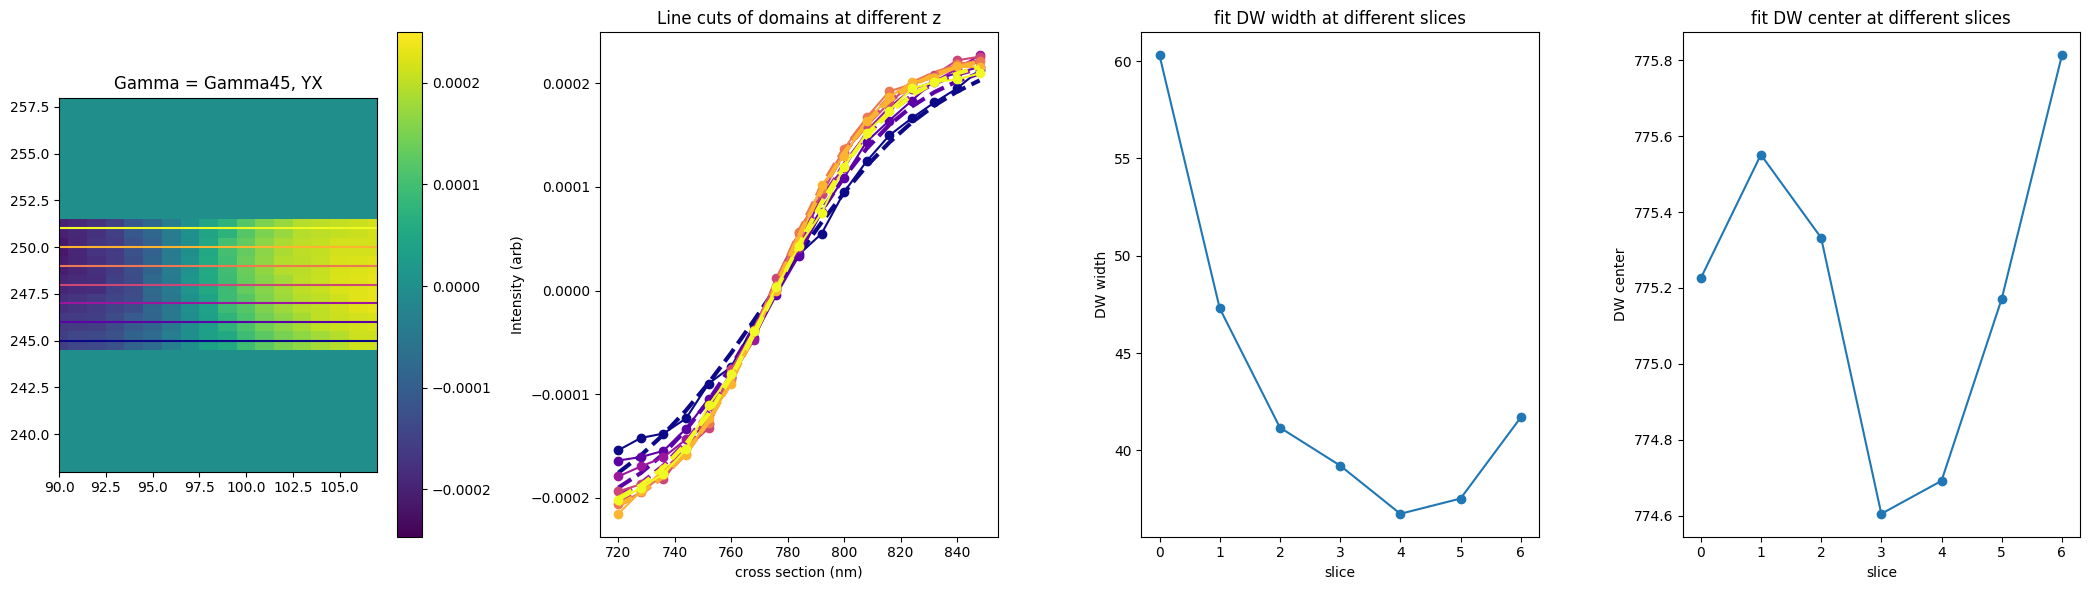

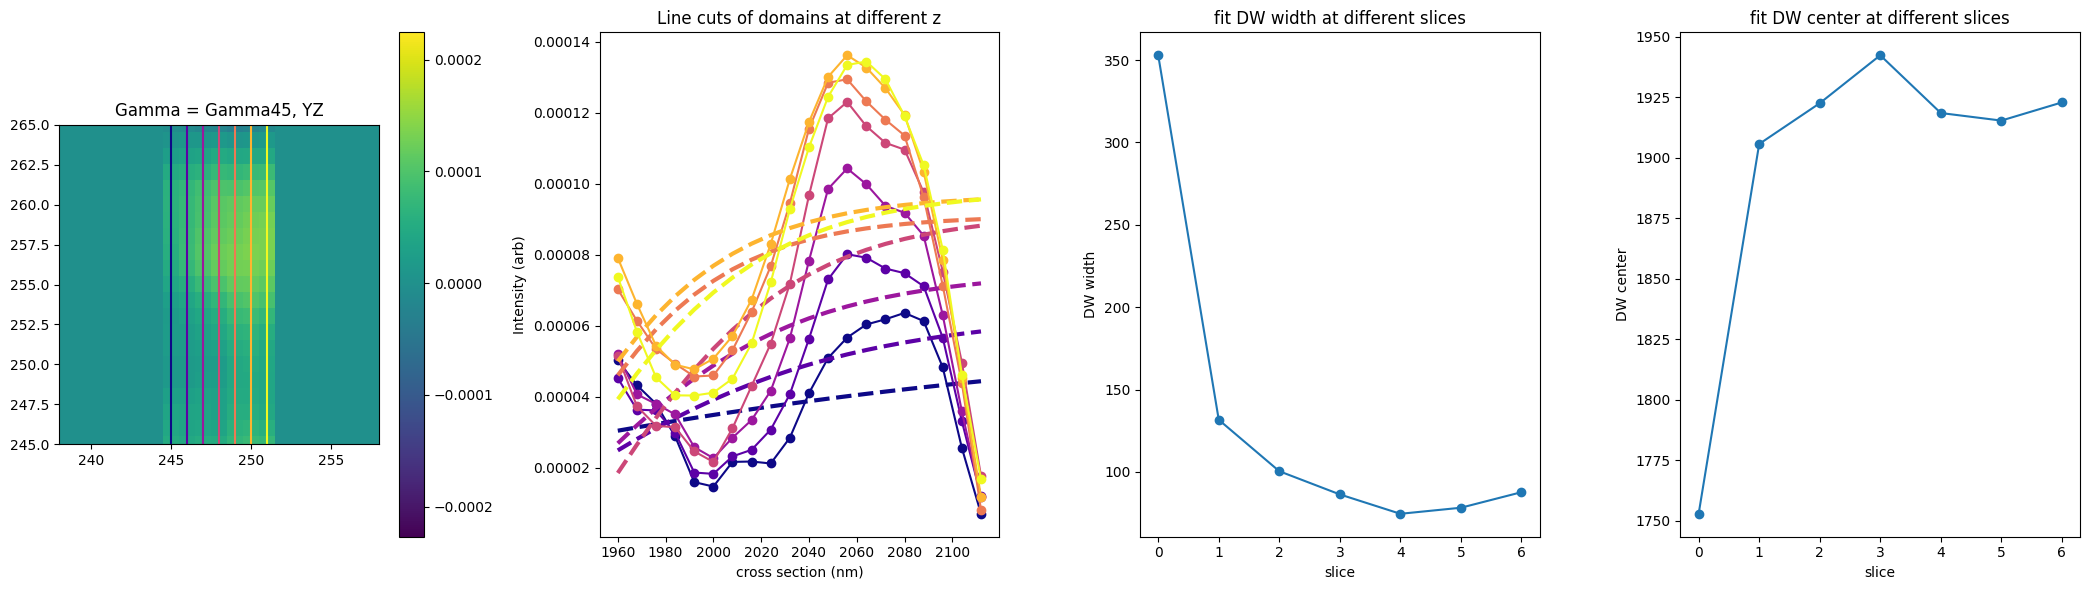

In [46]:
## c for constrained, m for masked
subsect_xh = [90, 107]
subsect_yh = [y_lo, y_hi]
shift_z = [0,1,2,3,4, 5, 6] 
linecut_m, dw_width_m, dw_center_m = reconstruct.plot_YX_linecut(recon_masked, subsect_xh, subsect_yh, shift_z, center1+s, sample, Gamma)

## v for vertical line cut
## c for constrained, m for masked
subsect_yv = [245, 265]
subsect_xv = [y_lo, y_hi]
linecut_mv, dw_width_mv, dw_center_mv = reconstruct.plot_YZ_linecut(recon_masked, subsect_xv, subsect_yv, shift_z, center1 + s, sample, Gamma) 

# Reconstruct with thickness as a constraint

  Iteration    0/100  |  max density inside mask: 0.0003
  Iteration   10/100  |  max density inside mask: 0.0033
  Iteration   20/100  |  max density inside mask: 0.0057
  Iteration   30/100  |  max density inside mask: 0.0078
  Iteration   40/100  |  max density inside mask: 0.0097
  Iteration   50/100  |  max density inside mask: 0.0113
  Iteration   60/100  |  max density inside mask: 0.0129
  Iteration   70/100  |  max density inside mask: 0.0143
  Iteration   80/100  |  max density inside mask: 0.0156
  Iteration   90/100  |  max density inside mask: 0.0168


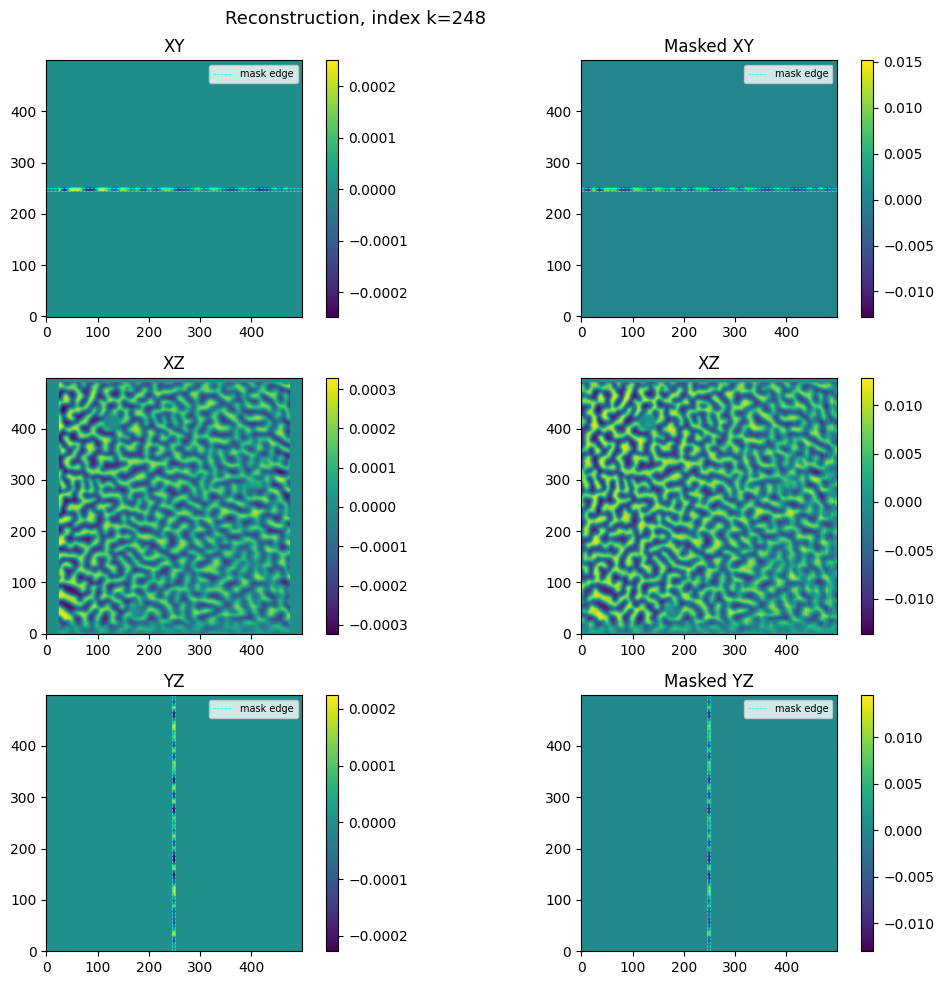

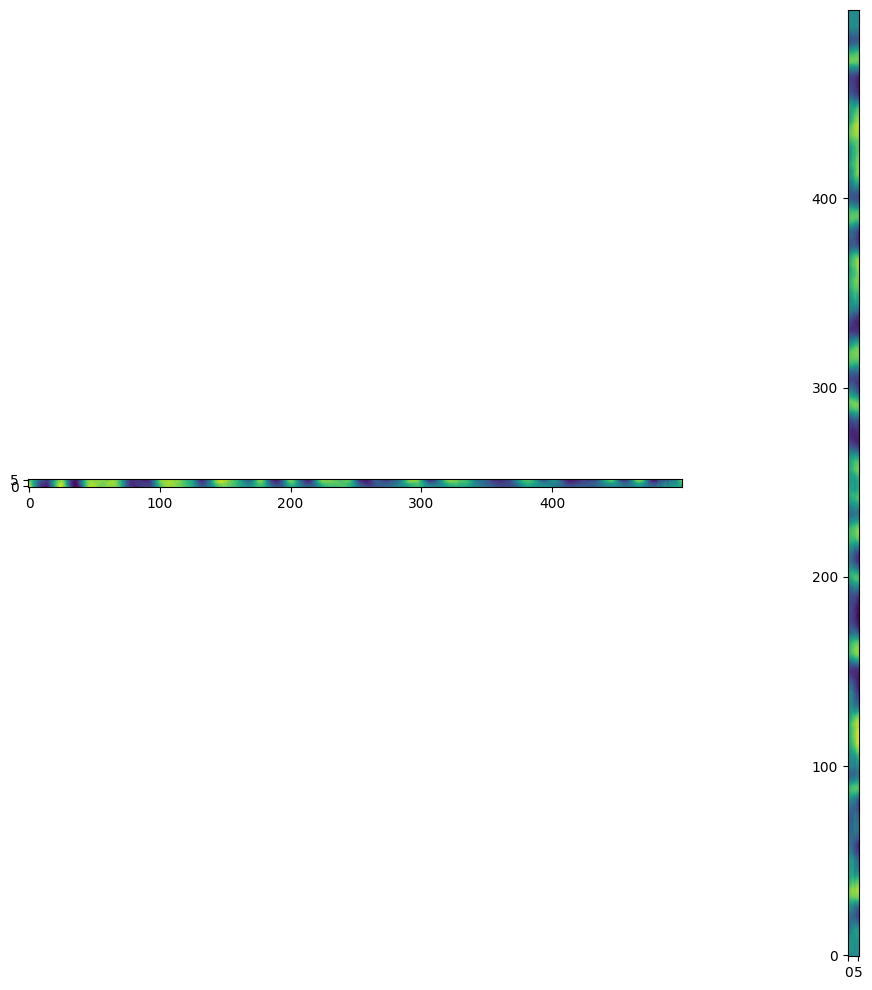

In [47]:
# Iterative recon with mask as constraint: drives out-of-mask voxels to zero during the iteration

recon_constrained = reconstruct.masked_sirt(rotated_0, ang, center2, mask, n_iter=100)
reconstruct.plot_crosssections_compare(film_center_y, recon_masked, recon_constrained, y_lo, y_hi)

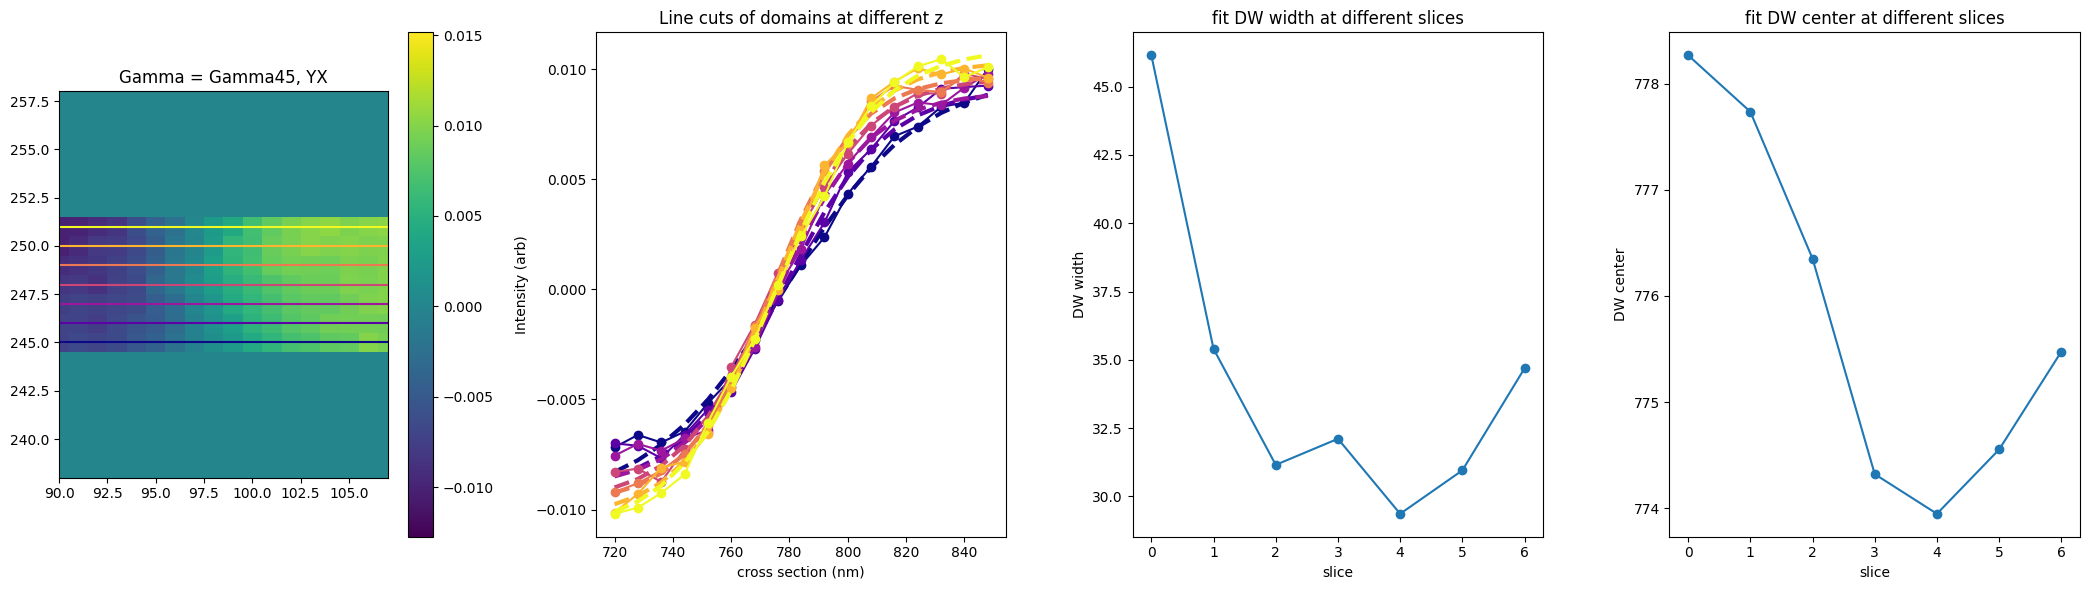

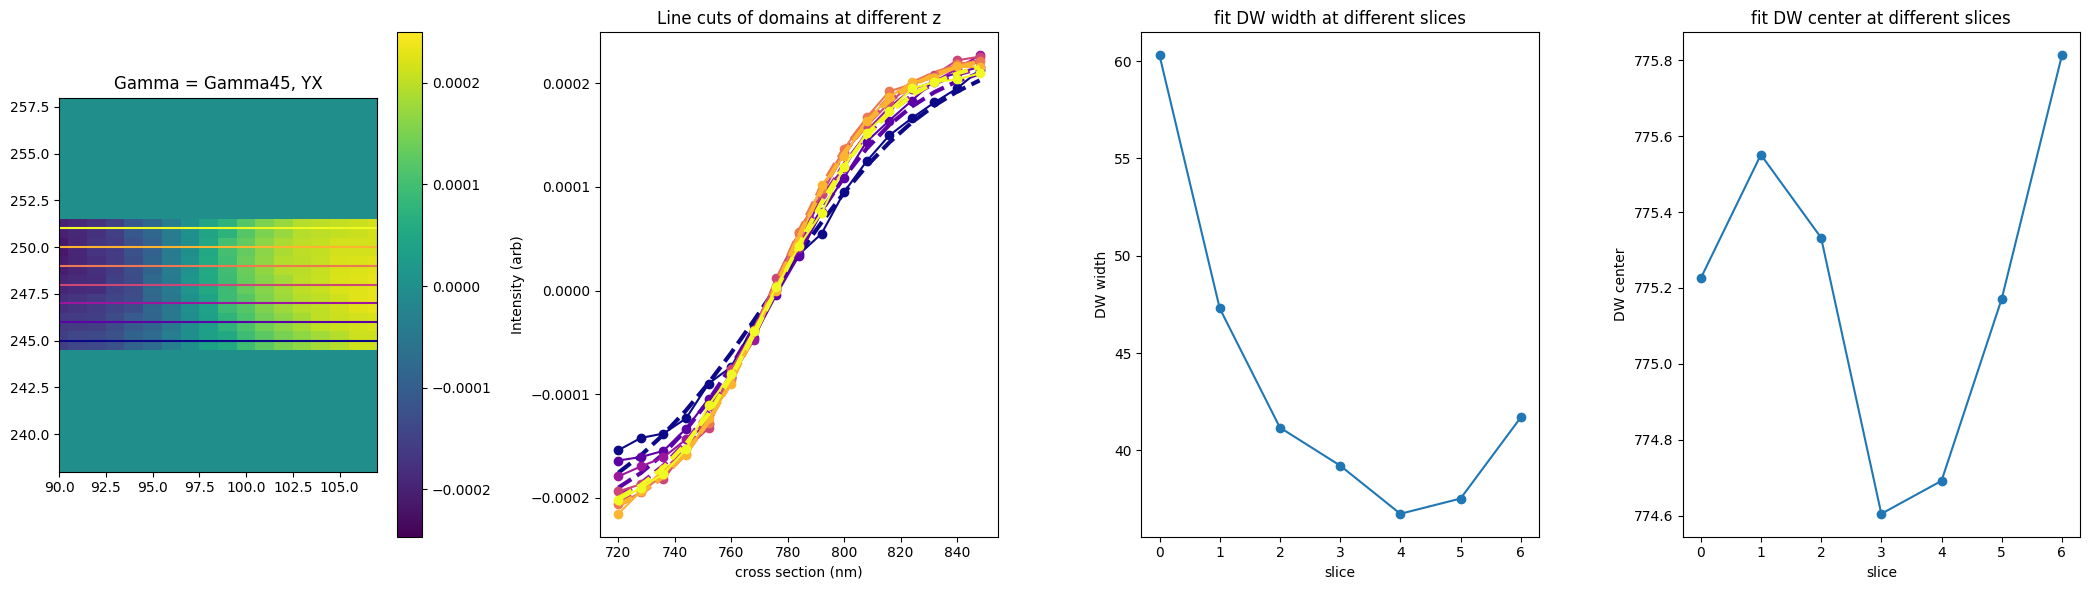

In [48]:
## c for constrained, m for masked
linecut_c, dw_width_c, dw_center_c = reconstruct.plot_YX_linecut(recon_constrained, subsect_xh, subsect_yh, shift_z, center1+s, sample, Gamma)
linecut_m, dw_width_m, dw_center_m = reconstruct.plot_YX_linecut(recon_masked, subsect_xh, subsect_yh, shift_z, center1+s, sample, Gamma)

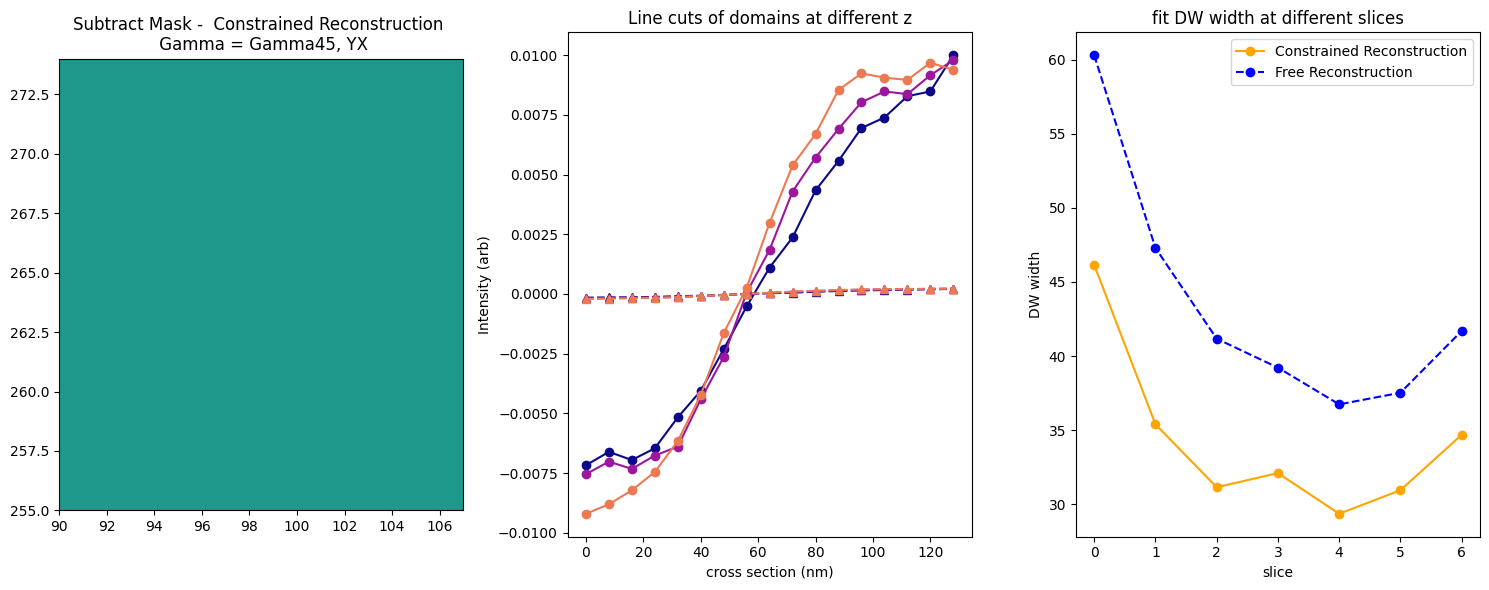

In [49]:
## compare constrained thickness to free thickness
fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_masked[k,:,:] - recon_constrained[k,:,:], cmap='viridis')
ax1.set_title(f'Subtract Mask -  Constrained Reconstruction \n Gamma = {Gamma}, YX')
ax1.set_xlim(subsect_xh[0],subsect_xh[1])
ax1.set_ylim(center1-2, center1+17)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')


z_to_plot = [0,2,4]
colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z))) 

for z in z_to_plot:
    x_fit = np.arange(len(linecut_c[z])) * pixel_size_nm
    ax2.plot(x_fit, linecut_c[z], color=colors[z], label=f'Constrained Reconstruction', marker='o')
    ax2.plot(x_fit, linecut_m[z], color=colors[z], linestyle = '--', label=f'Free Reconstruction', marker='^')
    # ax1.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--', label=f'Hyperbolic Fit {sample}, {Gamma},\n DW width = {hyperbolic_fit[2]:.2f} nm')
    
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(shift_z, np.abs(dw_width_c), marker='o', color = 'orange',  label=f'Constrained Reconstruction')
ax3.plot(shift_z, np.abs(dw_width_m), marker='o', color = 'blue', linestyle = '--',  label=f'Free Reconstruction')

ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.legend()
ax3.set_title('fit DW width at different slices')

plt.tight_layout()
plt.show()





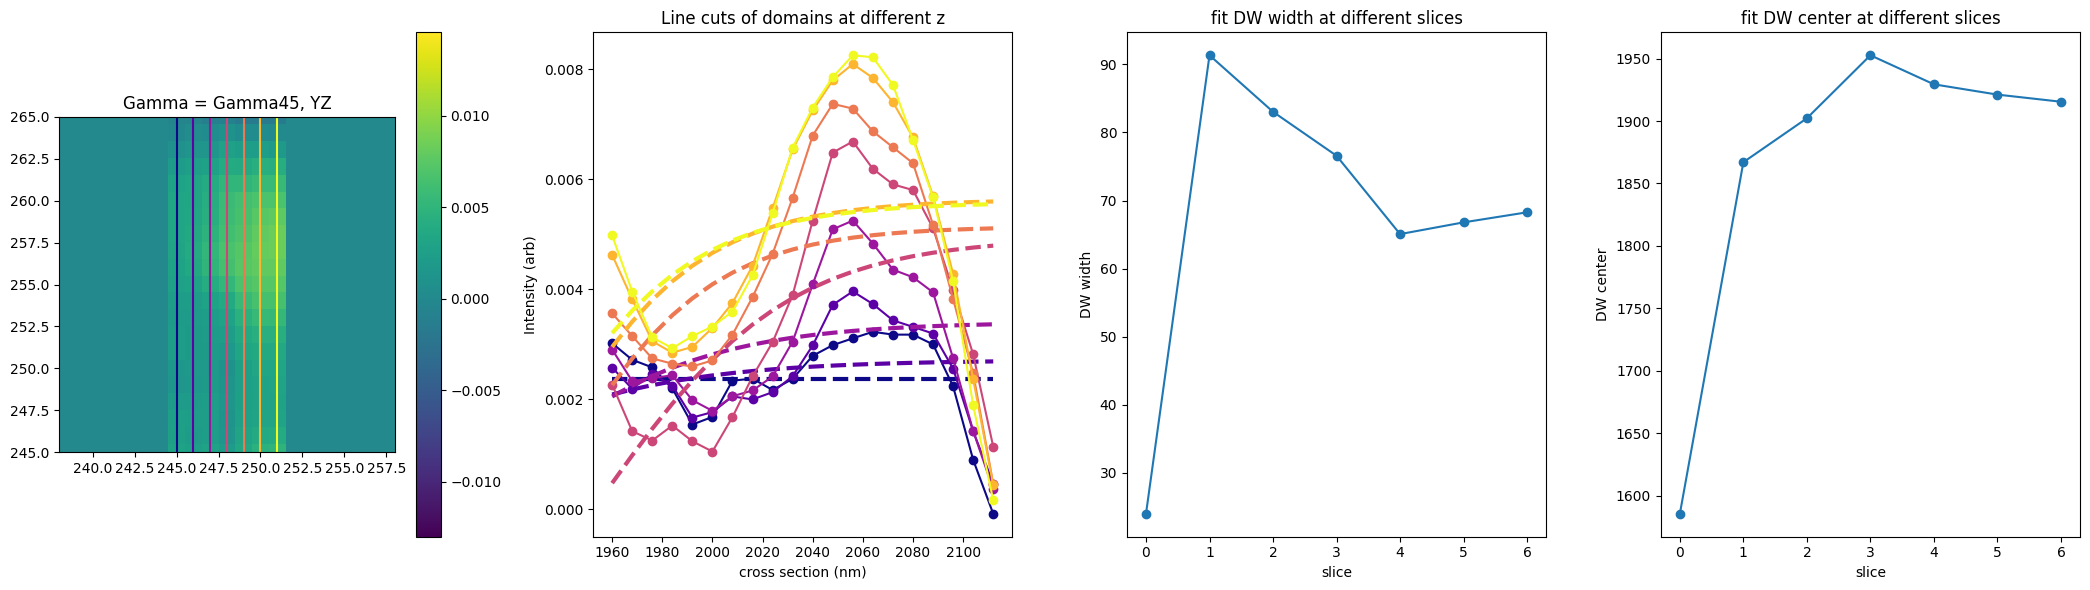

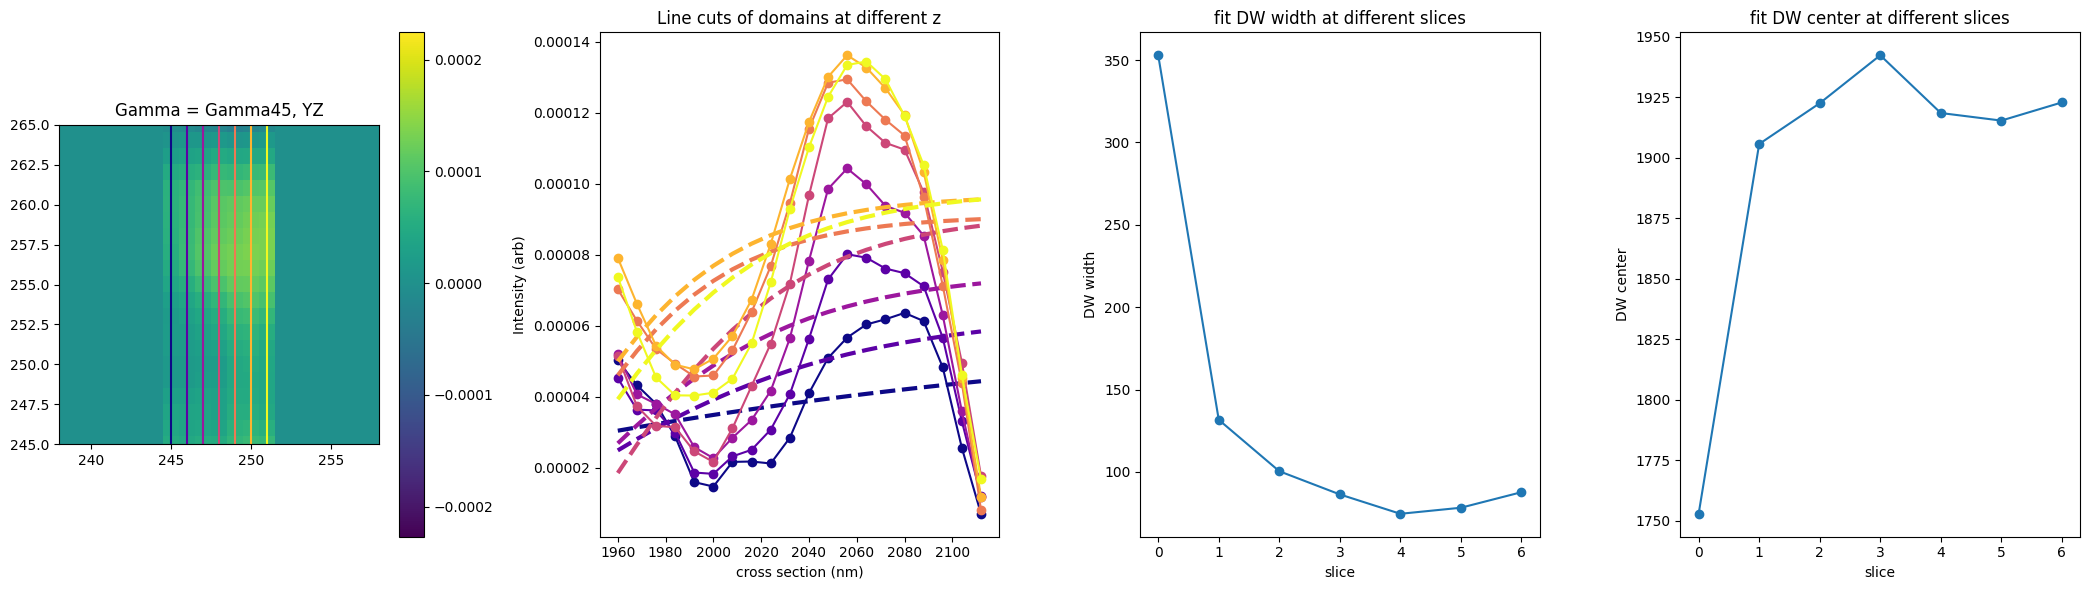

In [50]:
## v for vertical line cut
## c for constrained, m for masked

linecut_cv, dw_width_cv, dw_center_cv = reconstruct.plot_YZ_linecut(recon_constrained, subsect_xv, subsect_yv, shift_z, center1 + s, sample, Gamma)
linecut_mv, dw_width_mv, dw_center_mv = reconstruct.plot_YZ_linecut(recon_masked, subsect_xv, subsect_yv, shift_z, center1 + s, sample, Gamma) 



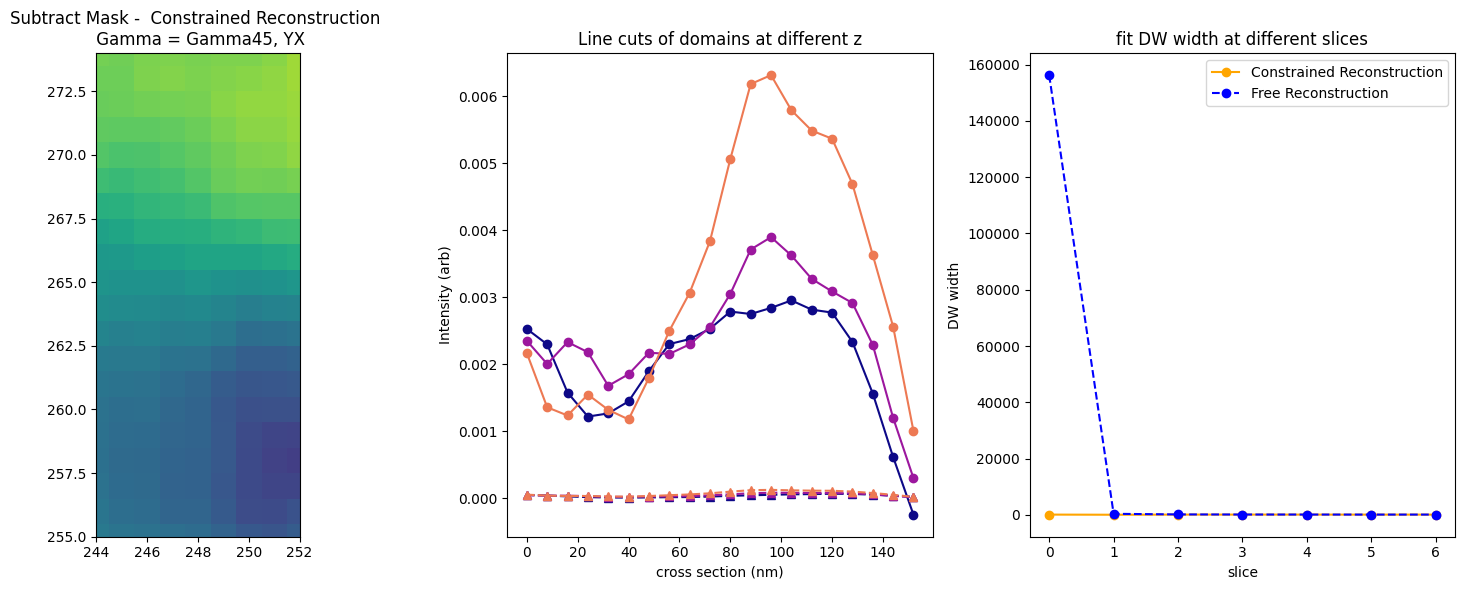

In [44]:
## compare constrained thickness to free thickness
fig = plt.figure(figsize=(15, 6))

ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_masked[:,:,k] - recon_constrained[:,:,k], cmap='viridis')
ax1.set_title(f'Subtract Mask -  Constrained Reconstruction \n Gamma = {Gamma}, YX')
ax1.set_xlim(subsect_xv[0],subsect_xv[1])
ax1.set_ylim(center1-2, center1+17)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))

for z in z_to_plot:
    x_fit = np.arange(len(linecut_cv[z])) * pixel_size_nm
    ax2.plot(x_fit, linecut_cv[z], color=colors[z], label=f'Constrained Reconstruction', marker='o')
    ax2.plot(x_fit, linecut_mv[z], color=colors[z], linestyle = '--', label=f'Free Reconstruction', marker='^')
    # ax1.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--', label=f'Hyperbolic Fit {sample}, {Gamma},\n DW width = {hyperbolic_fit[2]:.2f} nm')
    
ax3 = fig.add_subplot(1, 3, 3)
ax3.plot(shift_z, np.abs(dw_width_cv), marker='o', color = 'orange',  label=f'Constrained Reconstruction')
ax3.plot(shift_z, np.abs(dw_width_mv), marker='o', color = 'blue', linestyle = '--',  label=f'Free Reconstruction')

ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.legend()
ax3.set_title('fit DW width at different slices')

plt.tight_layout()
plt.show()

# Hough transform
## Goal 


## Tomopy automatic alignment
-Compare to manual shift

In [ ]:
#### apply a distortion correction to the tomographic recon using a polynomial model 
xcenter = 257 # center of distortion in x-direction from left 
ycenter = 257 # center of distortion in y-direction from top 
list_fact = [] # polynomial coefficients of the backward model
recon_shift_corrected = tomopy.prep.alignment.distortion_correction_proj(recon_shift, xcenter, ycenter, list_fact, ncore=None, nchunk=None)


In [ ]:
### align joint: alignms projection image stack using the joint re-projection, returns 3D stack of projections and error

proj_align_joint = tomopy.prep.alignment.align_joint(rotated_0, ang,center=center1, algorithm='gridrec')



In [ ]:
print(proj_align_joint[0].shape)
recon_align_joint = tomopy.recon(proj_align_joint[0], ang, center=center1, algorithm='gridrec', sinogram_order=False) ### 
recon_align_joint = tomopy.circ_mask(recon_align_joint, axis=0, ratio=0.90) 

k = 257
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_align_joint[k,:,:])
ax1.set_title(f'Gamma = {Gamma},  YX')
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(recon_align_joint[:,k,:])
ax2.set_title('ZX')
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(recon_align_joint[:,:,k])
ax3.set_title('ZY')

In [ ]:
### align seq: alignms projection image using the sequential re-projection algorithm

proj_align_seq = tomopy.prep.alignment.align_seq(rotated_0, ang, center=center1, algorithm='gridrec')

recon_align_seq = tomopy.recon(proj_align_seq[0], ang, center=center1, algorithm='gridrec', sinogram_order=False) ### 
recon_align_seq = tomopy.circ_mask(recon_align_seq, axis=0, ratio=0.90) 

k = 257
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_align_seq[k,:,:])
ax1.set_title(f'Gamma = {Gamma},  YX')
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(recon_align_seq[:,k,:])
ax2.set_title('ZX')
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(recon_align_seq[:,:,k])
ax3.set_title('ZY')

In [ ]:

recon_align_seq = tomopy.recon(proj_align_seq[0], ang, center=center1, algorithm='gridrec', sinogram_order=False) ### 
recon_align_seq = tomopy.circ_mask(recon_align_seq, axis=0, ratio=0.90) 

k = 257
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_align_seq[k,:,:])
ax1.set_title(f'Gamma = {Gamma},  YX')
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(recon_align_seq[:,k,:])
ax2.set_title('ZX')
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(recon_align_seq[:,:,k])
ax3.set_title('ZY')

In [ ]:
save = False
if save == True: 
    print('saved')
    tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_align_joint.tiff", recon_align_joint.astype(np.float32))
    tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_align_seq.tiff", recon_align_seq.astype(np.float32))
else: 
    print('no save')

In [ ]:
## determine angular offset

p0 = np.array([275, 0])
p1 = np.array([254, 514])

dx = p1[0] - p0[0]
print(f'dx = p1 {p1[0]} - p0 {p0[0]} = {dx}')
dy = abs(p1[1] - p0[1])
print(f'dy = p1 {p1[1]} - p0 {p0[1]} = {dy}')

theta_rad = np.arctan2(dx, dy)
theta_deg = np.degrees(theta_rad)

print(theta_deg)

In [ ]:
375*2

In [ ]:
min_x = 120
max_x = 145

shift_z = [-4,-3,-2,-1]
skipped = []
#shift_z = [0]

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))

linecut_z = [ ]
dw_width_bloch = []
dw_center = []

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[k,:,:], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, YX')
ax1.set_xlim(min_x, max_x)
ax1.set_ylim(250, 290)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

ax3 = fig.add_subplot(1, 3, 3)
ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.set_title('fit DW width at different slices')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    p0 = (275 + z, 0)
    p1 = (254 + z, 514)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[k, :, :],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    
    linecut_fit = linecut[min_x:max_x]
    x_fit = x[min_x:max_x]
    linecut_z.append(linecut_fit)
    
    
    hyperbolic_fit, hyperbolic_error = fit_hyperbolic(x_fit, linecut_fit)
    hyperbolic_plot = hyperbolic(x_fit, *hyperbolic_fit)
    dw_width_bloch.append(hyperbolic_fit[2]) ## might need to be converted into nm
    dw_center.append(hyperbolic_fit[1])
    
    if z in skipped: 
        print(f'skipped {z}')
    else:
        # Plot the line on the image
        ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], label=f'shift {z} nm')

        # Overlay linecut in second subplot
        ax2.plot(x_fit, linecut_fit, color=colors[i], label=f'shift {z} nm', marker='o')
        ax2.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--', label=f'Hyperbolic Fit,\n DW width = {hyperbolic_fit[2]:.2f} nm')

# Add legends

#ax2.legend(bbox_to_anchor=(1.25, 0.55))
#ax2.legend()
# ax2.set_xlim(x[min_x],x[max_x])


ax3.plot(shift_z, np.abs(dw_width_bloch), marker='o')
#ax3.plot(shift_z, dw_center, marker='o')

plt.tight_layout()
plt.show()





In [ ]:
top = dw_width_bloch
print(top)

In [ ]:
top_x = [0,1,2,3,4]
bottom_x = [-4,-3,-2,-1]
plt.scatter(top_x, top, color = 'tab:blue', marker = 'o')
plt.scatter(bottom_x,np.abs(dw_width_bloch), color = 'tab:blue', marker = 'o' )
plt.xlabel('slice')
plt.ylabel('DW width')
plt.title('fit DW width at different slices')

In [ ]:
min = 85
max = 135

fig = plt.figure(figsize=(6, 12))
ax1 = fig.add_subplot(2, 1, 1)
ax1.imshow(recon_shift[k,:,:])
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', alpha = 0.5, label = 'manually placed linecut')
ax1.set_title(f' Section ({min},{max}) \n Gamma = {Gamma},  YX')
ax1.legend()
ax1.set_xlim(min,max)
ax1.set_ylim(230,290)
ax2 = fig.add_subplot(2, 1, 2)
ax2.plot(linecut_manual,marker = 'o', color = 'red')
ax2.set_xlim(min,max)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

In [ ]:
k = 257
linecut_horizontal = recon_shift[:,:,k][:,k]

# p0 = (275, 0)
# p1 = (257, 514)
p0 = (0, 275)
p1 = (514, 257)

linecut_manual = profile_line(
    recon_shift[:,:,k],
    src=p0,
    dst=p1,
    linewidth=1,     # average over pixels perpendicular to line
    order=1,         # bilinear interpolation
    mode='reflect'
)

pixel_size_nm = 8.0
x = np.arange(len(linecut_manual)) * pixel_size_nm

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[:,:,k])
ax1.axvline(k, color = 'black', label = 'vertical linecut')
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', label = 'manually placed linecut')
ax1.set_title(f'Gamma = {Gamma},  ZY')
ax1.legend(loc='upper left')
ax1.set_xlim(0,514)
ax1.set_ylim(0,514)
ax2 = fig.add_subplot(1, 2, 2)
# ax2.plot(x, linecut_horizontal, color = 'black', linewidth = '0.5')
ax2.plot(x, linecut_manual, color = 'red')
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

min = 85
max = 135
fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[:,:,k])
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', label = 'manually placed linecut')
ax1.set_title(f'Gamma = {Gamma},  YX')
ax1.legend()
ax1.set_ylim(min,max)
ax1.set_xlim(250,290)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(x, linecut_manual, marker = 'o', color = 'red')
ax2.set_xlim(x[min],x[max])
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

In [ ]:
min_x = 120
max_x = 145

shift_z = [ -3, -2, -1, 0,1,2,3,4]
skipped = [-3, -2, 0,1,2,3,4]
#shift_z = [0]

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))

linecut_z = [ ]
dw_width_bloch = []

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[k,:,:], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, YX')
ax1.set_xlim(min_x, max_x)
ax1.set_ylim(250, 290)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

ax3 = fig.add_subplot(1, 3, 3)
ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.set_title('fit DW width at different slices')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    p0 = (275 + z, 0)
    p1 = (254 + z, 514)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[k, :, :],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    
    linecut_fit = linecut[min_x:max_x]
    x_fit = x[min_x:max_x]
    linecut_z.append(linecut_fit)
    
    
    hyperbolic_fit, hyperbolic_error = fit_hyperbolic(x_fit, linecut_fit)
    hyperbolic_plot = hyperbolic(x_fit, *hyperbolic_fit)
    dw_width_bloch.append(hyperbolic_fit[2]) ## might need to be converted into nm
    
    if z in skipped: 
        print(f'skipped {z}')
    else:
        # Plot the line on the image
        ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], label=f'shift {z} nm')

        # Overlay linecut in second subplot
        ax2.plot(x_fit, linecut_fit, color=colors[i], label=f'shift {z} nm', marker='o')
        ax2.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--', label=f'Hyperbolic Fit,\n DW width = {hyperbolic_fit[2]:.2f} nm')

# Add legends

#ax2.legend(bbox_to_anchor=(1.25, 0.55))
ax2.legend()
# ax2.set_xlim(x[min_x],x[max_x])


ax3.plot(shift_z, dw_width_bloch, marker='o')

plt.tight_layout()
plt.show()

In [ ]:
min_x = 300
max_x = 350

shift_z = [ -3, -2, -1,0,1,2,3]
skipped = []

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))
linecut_z = [ ]
dw_width_bloch = []
dw_center = []

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[:,:,k], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, ZY')
ax1.set_ylim(min_x, max_x)
ax1.set_xlim(240, 280)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

ax3 = fig.add_subplot(1, 3, 3)
ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.set_title('fit DW width at different slices')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    
    p0 = (0, 275 + z)
    p1 = (514, 254 + z)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[:, :, k],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    linecut_fit = linecut[min_x:max_x]
    x_fit = x[min_x:max_x]
    linecut_z.append(linecut_fit)
    
    hyperbolic_fit, hyperbolic_error = fit_hyperbolic(x_fit, linecut_fit)
    hyperbolic_plot = hyperbolic(x_fit, *hyperbolic_fit)
    print(hyperbolic_fit[2])
    dw_width_bloch.append(hyperbolic_fit[2]) ## might need to be converted into nm
    dw_center.append(hyperbolic_fit[1]) 
    if z in skipped: 
        print(f'skipped {z}')
    else:
        # Plot the line on the image
        ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], alpha = 0.5, label=f'shift {z} nm')

        # Overlay linecut in second subplot
        #ax2.plot(x_fit, linecut_fit, color=colors[i], label=f'shift {z} nm', marker='o')
        ax2.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--') #label=f'Hyperbolic Fit,\n DW width = {hyperbolic_fit[2]:.2f} nm'

# Add legends

ax2.legend()
# ax2.set_xlim(x[min_x],x[max_x])
ax3.scatter(shift_z, np.abs(dw_width_bloch), marker='o')
#ax3.plot(shift_z, dw_center, marker='o')
plt.tight_layout()
plt.show()

# Proj 45

In [ ]:
## shift image center to the center of rotation determined in Gamma_alignment_final 
## Rotate the projection 90 degrees around this point so that the axis of rotation is vertical
vertical_angle = 90
k = 100
Gamma = 45
rotated_45_0 = rotate_about_COR(proj_45[k], vertical_angle, yo_0, xo_0, order=3, plot = True)

rotated_45 = [ ]
for i in range(proj_0.shape[0]):
    rotated = rotate_about_COR(proj_45[i], vertical_angle, yo_0, xo_0, order=3, plot = False)
    rotated_45.append(rotated)
rotated_45 = np.array(rotated_45)
print(rotated_45.shape)

### quick tomography check 

center1 = 257
recon_45 = tomopy.recon(rotated_45, ang, center=center1, algorithm='gridrec', sinogram_order=False) ### 
recon_45 = tomopy.circ_mask(recon_45, axis=0, ratio=0.90) 
# recon_0 = tomopy.circ_mask(recon_0, axis=1, ratio=0.90) 
# recon_0 = tomopy.circ_mask(recon_0, axis=2, ratio=0.90) 
## Plot and check centering
k = 257
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_45[k,:,:])
ax1.set_title(f'Gamma = {Gamma},  YX')
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(recon_45[:,k,:])
ax2.set_title('ZX')
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(recon_45[:,:,k])
ax3.set_title('ZY')

In [ ]:
save = False
if save == True: 
    print('saved')
    tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_noshift.tiff", recon_0.astype(np.float32))
else: 
    print('no save')

In [ ]:
Gamma = 45
center1 = 257 #257 due to shifting COR to the center pixel and rotating around that
shifts = [-5, 13, 25]
    
for i in shifts: 

    ## Reconstruction with full image 
    ## Gamma = 0
    center = center1 + i
    #print(f'rotation center = {center}')
    recon_45 = tomopy.recon(rotated_45, ang, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon_45 = tomopy.circ_mask(recon_45, axis=0, ratio=0.90)
    # recon_0 = tomopy.circ_mask(recon_0, axis=1, ratio=0.90) 
    # recon_0 = tomopy.circ_mask(recon_0, axis=2, ratio=0.90) 
    ## Plot and check centering
    k = 257
    fig = plt.figure(figsize=(10, 6))
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(recon_45[k,:,:])
    ax1.set_title(f'Gamma = {Gamma}, center = {center}, shift = {i} \n YX')
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(recon_45[:,k,:])
    ax2.set_title('ZX')
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.imshow(recon_45[:,:,k])
    ax3.set_title('ZY')

In [ ]:
## shift image center by 13 based on Γ=0 above!!!!!
shifts = 13
center2 = center1+shifts

recon_shift = tomopy.recon(rotated_45, ang, center=center2, algorithm='gridrec', sinogram_order=False) ### 
recon_shift = tomopy.circ_mask(recon_shift, axis=0, ratio=0.90) 

k = 257
fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[k,:,:])
ax1.set_title(f'Gamma = {Gamma},  YX')
ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(recon_shift[:,k,:])
ax2.set_title('ZX')
ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(recon_shift[:,:,k])
ax3.set_title('ZY')

In [ ]:
save = False
if save == True: 
    print('saved')
    tifffile.imwrite(f"Gamma_45_XMCD_recon_vertical_shifted13.tiff", recon_shift.astype(np.float32))
else: 
    print('no save')

## linecuts

In [ ]:
k = 257
linecut_horizontal = recon_shift[k,:,:][k,:]

p0 = (269, 0)
p1 = (264, 514)

linecut_manual = profile_line(
    recon_shift[k,:,:],
    src=p0,
    dst=p1,
    linewidth=1,     # average over pixels perpendicular to line
    order=1,         # bilinear interpolation
    mode='reflect'
)

pixel_size_nm = 8.0
x = np.arange(len(linecut_manual)) * pixel_size_nm

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[k,:,:])
# ax1.axhline(k, color = 'black', label = 'horizontal linecut')
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', label = 'manually placed linecut')
ax1.set_title(f'Gamma = {Gamma},  YX')
ax1.legend()
ax1.set_xlim(0,514)
ax2 = fig.add_subplot(1, 2, 2)
# ax2.plot(x, linecut_horizontal, color = 'black', linewidth = '0.5')
ax2.plot(x, linecut_manual, color = 'red')
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

In [ ]:
min_x = 120
max_x = 131


shift_z = [ -4,-3,-2,-1, 0, 1, 2, 3]
skipped = []
#shift_z = [0]

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))

linecut_z = [ ]
dw_width_bloch = []
dw_center = []

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[k,:,:], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, YX')
ax1.set_xlim(min_x, max_x)
ax1.set_ylim(250, 290)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

ax3 = fig.add_subplot(1, 3, 3)
ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.set_title('fit DW width at different slices')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    p0 = (269 +z, 0)
    p1 = (264 +z, 514)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[k, :, :],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    
    linecut_fit = linecut[min_x:max_x]
    x_fit = x[min_x:max_x]
    linecut_z.append(linecut_fit)
    
    
    hyperbolic_fit, hyperbolic_error = fit_hyperbolic(x_fit, linecut_fit)
    hyperbolic_plot = hyperbolic(x_fit, *hyperbolic_fit)
    dw_width_bloch.append(hyperbolic_fit[2]) ## might need to be converted into nm
    dw_center.append(hyperbolic_fit[1])
    
    if z in skipped: 
        print(f'skipped {z}')
    else:
        # Plot the line on the image
        ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], label=f'shift {z} nm')

        # Overlay linecut in second subplot
        #ax2.plot(x_fit, linecut_fit, color=colors[i], label=f'shift {z} nm', marker='o')
        ax2.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--', label=f'Hyperbolic Fit, shift {z} nm \n DW width = {hyperbolic_fit[2]:.2f} nm')

# Add legends

#ax2.legend(bbox_to_anchor=(1.25, 0.55))
ax2.legend(loc = 'lower left', fontsize = 8)
# ax2.set_xlim(x[min_x],x[max_x])


ax3.plot(shift_z, np.abs(dw_width_bloch), marker='o')
#ax3.plot(shift_z, dw_center, marker='o')

plt.tight_layout()
plt.show()

In [ ]:
min_x = 109
max_x = 160

# shift_z = [-5, -4, -3, -2, -1,0,1,2,3]
shift_z = [0]

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))
linecut_z = [ ]

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[k,:,:], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, YX')
ax1.set_xlim(min_x, max_x)
ax1.set_ylim(250, 290)

ax2 = fig.add_subplot(1, 2, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    p0 = (269 +z, 0)
    p1 = (264 +z, 514)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[k, :, :],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    linecut_z.append(linecut)

    # Plot the line on the image
    ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], alpha = 0.5, label=f'shift {z} nm')

    # Overlay linecut in second subplot
    ax2.plot(linecut, color=colors[i], label=f'shift {z} nm', marker='o')

# Add legends

# ax2.legend(bbox_to_anchor=(1.25, 0.55))
ax2.legend()
ax2.set_xlim(min_x,max_x)
plt.tight_layout()
plt.show()

In [ ]:
k = 257
linecut_horizontal = recon_shift[:,:,k][:,k]


p0 = (0, 269)
p1 = (514, 264)


linecut_manual = profile_line(
    recon_shift[:,:,k],
    src=p0,
    dst=p1,
    linewidth=1,     # average over pixels perpendicular to line
    order=1,         # bilinear interpolation
    mode='reflect'
)

pixel_size_nm = 8.0
x = np.arange(len(linecut_manual)) * pixel_size_nm

fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[:,:,k])
# ax1.axvline(k, color = 'black', label = 'vertical linecut')
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', label = 'manually placed linecut')
ax1.set_title(f'Gamma = {Gamma},  ZY')
ax1.legend(loc='upper left')
ax1.set_xlim(0,514)
ax1.set_ylim(0,514)
ax2 = fig.add_subplot(1, 2, 2)
# ax2.plot(x, linecut_horizontal, color = 'black', linewidth = '0.5')
ax2.plot(x, linecut_manual, color = 'red')
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

min = 230
max = 290
fig = plt.figure(figsize=(12, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[:,:,k])
ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], 'r-', label = 'manually placed linecut')
ax1.set_title(f'Gamma = {Gamma},  YX')
ax1.legend()
ax1.set_ylim(min,max)
ax1.set_xlim(250,290)
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(linecut_manual, marker = 'o', color = 'red')
ax2.set_xlim(min,max)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Inentisy (arb)')
ax2.set_title('Line cut of domains')

In [ ]:
min_x = 230
max_x = 290

shift_z = [ -3, -2, -1,0,1,2,3]

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))
linecut_z = [ ]

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(recon_shift[:,:,k], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, ZY')
ax1.set_ylim(min_x, max_x)
ax1.set_xlim(240, 280)

ax2 = fig.add_subplot(1, 2, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    
    p0 = (0, 269 + z)
    p1 = (514, 264 + z)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[:, :, k],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    linecut_z.append(linecut)

    # Plot the line on the image
    ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], alpha = 0.5, label=f'shift {z} nm')

    # Overlay linecut in second subplot
    ax2.plot(linecut, color=colors[i], label=f'shift {z} nm', marker='o')

# Add legends

ax2.legend(bbox_to_anchor=(1.25, 0.55))
ax2.set_xlim(min_x,max_x)
plt.tight_layout()
plt.show()

In [ ]:
min_x = 260
max_x = 287


shift_z = [ -3, -2, -1,0,1,2,3]
skipped = []

colors = plt.cm.plasma(np.linspace(0, 1, len(shift_z)))
linecut_z = [ ]
dw_width_bloch = []
dw_center = []

fig = plt.figure(figsize=(15, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(recon_shift[:,:,k], cmap='viridis')
ax1.set_title(f'Gamma = {Gamma}, ZY')
ax1.set_ylim(min_x, max_x)
ax1.set_xlim(240, 280)

ax2 = fig.add_subplot(1, 3, 2)
ax2.set_xlabel('cross section (nm)')
ax2.set_ylabel('Intensity (arb)')
ax2.set_title('Line cuts of domains at different z')

ax3 = fig.add_subplot(1, 3, 3)
ax3.set_xlabel('slice')
ax3.set_ylabel('DW width')
ax3.set_title('fit DW width at different slices')


for i, z in enumerate(shift_z):
    # Define start and end points for the linecut
    
    p0 = (0, 269 + z)
    p1 = (514, 264 + z)

    # Compute the linecut
    linecut = profile_line(
        recon_shift[:, :, k],
        src=p0,
        dst=p1,
        linewidth=1,
        order=1,
        mode='reflect'
    )
    linecut_fit = linecut[min_x:max_x]
    x_fit = x[min_x:max_x]
    linecut_z.append(linecut_fit)
    
    hyperbolic_fit, hyperbolic_error = fit_hyperbolic(x_fit, linecut_fit)
    hyperbolic_plot = hyperbolic(x_fit, *hyperbolic_fit)
    print(hyperbolic_fit[2])
    dw_width_bloch.append(hyperbolic_fit[2]) ## might need to be converted into nm
    dw_center.append(hyperbolic_fit[1]) 
    if z in skipped: 
        print(f'skipped {z}')
    else:
        # Plot the line on the image
        ax1.plot([p0[1], p1[1]], [p0[0], p1[0]], color=colors[i], alpha = 0.5, label=f'shift {z} nm')

        # Overlay linecut in second subplot
        #ax2.plot(x_fit, linecut_fit, color=colors[i], label=f'shift {z} nm', marker='o')
        ax2.plot(x_fit, hyperbolic_plot, color=colors[i], linewidth=3, linestyle = '--') #label=f'Hyperbolic Fit,\n DW width = {hyperbolic_fit[2]:.2f} nm'

# Add legends

ax2.legend()
# ax2.set_xlim(x[min_x],x[max_x])
ax3.scatter(shift_z, np.abs(dw_width_bloch), marker='o')
#ax3.plot(shift_z, dw_center, marker='o')
plt.tight_layout()
plt.show()

# FSC

In [ ]:
def reconstruct_and_save(proj_sub, ang_sub, center, tag, save = True):
    """
    proj_sub : (n, ny, nx)
    ang_sub  : (n,)
    tag      : descriptive string for saving
    """
    print(f"{tag}: using {len(ang_sub)} angles")

    # recon = tomopy.recon(proj_sub, ang_sub, algorithm='gridrec', sinogram_order=False)

    recon = tomopy.recon(proj_sub, ang_sub, center=center, algorithm='gridrec', sinogram_order=False) ### 
    recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) 

    if save:
        tifffile.imwrite(f"{Gamma}_{tag}.tif", recon.astype(np.float32))

    return recon

def resolution_at_threshold(freq, fsc, threshold):
    idx = np.where(fsc < threshold)[0]
    if len(idx) == 0:
        return np.nan
    return 1 / freq[idx[0]]

def fourier_shell_correlation(
    vol1,
    vol2,
    voxel_size,
    n_shells=150, ######## good assumption based on image size
    plot=True
):
    """
    Compute Fourier Shell Correlation (FSC) between two 3D volumes.

    Parameters
    ----------
    vol1, vol2 : ndarray
        3D numpy arrays (Nz, Ny, Nx)
    voxel_size : float
        Voxel size in real space (same units as desired resolution)
    n_shells : int
        Number of frequency shells
    plot : bool
        Whether to plot FSC curve

    Returns
    -------
    freq : ndarray
        Spatial frequency (1 / length units)
    fsc : ndarray
        FSC values
    resolution_05 : float
        Resolution at FSC = 0.5 (same units as voxel_size)
    resolution_0143 : float
        Resolution at FSC = 0.143
    """
    vol1 = vol1.astype(np.float32)
    vol2 = vol2.astype(np.float32)
    assert vol1.shape == vol2.shape, "Volumes must have same shape"

    # Fourier transforms
    F1 = np.fft.rfftn(vol1)
    F2 = np.fft.rfftn(vol2)

    # Frequency grid
    nz, ny, nx = vol1.shape
    kz = np.fft.rfftfreq(nz, d=voxel_size).astype(np.float32)
    ky = np.fft.rfftfreq(ny, d=voxel_size).astype(np.float32)
    kx = np.fft.rfftfreq(nx, d=voxel_size).astype(np.float32)
    
    print(F1.shape)
    print(len(kz), len(ky), len(kx))

    # KZ, KY, KX = np.meshgrid(kz, ky, kx, indexing='ij')
    # K = np.sqrt(KX**2 + KY**2 + KZ**2)

    # Shell bins
    k_nyquist_x = np.max((kx))
    k_nyquist_y = np.max((ky))
    k_nyquist_z = np.max((kz))

    k_max = min(k_nyquist_x, k_nyquist_y, k_nyquist_z)
    
    shell_edges = np.linspace(0, k_max, n_shells + 1)

    fsc = np.zeros(n_shells, dtype=np.float32)
    freq = 0.5 * (shell_edges[:-1] + shell_edges[1:])

    for i in range(n_shells):
            kmin2 = shell_edges[i]**2
            kmax2 = shell_edges[i+1]**2

            num = 0.0
            den1 = 0.0
            den2 = 0.0

            for iz, kzv in enumerate(kz):
                kz2 = kzv * kzv
                for iy, kyv in enumerate(ky):
                    ky2 = kyv * kyv
                    r2 = kz2 + ky2 + kx*kx  # vectorized over x

                    mask = (r2 >= kmin2) & (r2 < kmax2)
                    if not np.any(mask):
                        continue

                    f1 = F1[iz, iy, mask]
                    f2 = F2[iz, iy, mask]

                    num += np.sum(f1 * np.conj(f2)).real
                    den1 += np.sum(np.abs(f1)**2)
                    den2 += np.sum(np.abs(f2)**2)

            fsc[i] = num / np.sqrt(den1 * den2) if den1 > 0 and den2 > 0 else 0
        

#####################################################################
    #fsc, freq = compute_fsc(n_shells,shell_edges, F1, F2, K, mask = False )


    # fsc = np.zeros(n_shells)
    # freq = np.zeros(n_shells)

    # # min_voxels = 50  # or something reasonable
    # # valid_shells = []

    # for i in range(n_shells):
    #     shell_mask = (K >= shell_edges[i]) & (K < shell_edges[i + 1])

    #     # if np.count_nonzero(shell_mask) < min_voxels:
    #     #     break
    #     # valid_shells.append(i)
        
    #     F1_shell = F1[shell_mask]
    #     F2_shell = F2[shell_mask]

    #     if F1_shell.size == 0:
    #         fsc[i] = np.nan
    #         continue

    #     num = np.sum(F1_shell * np.conj(F2_shell))
    #     den = np.sqrt(
    #         np.sum(np.abs(F1_shell)**2) *
    #         np.sum(np.abs(F2_shell)**2)
    #     )

    #     fsc[i] = np.real(num / den)
    #     freq[i] = 0.5 * (shell_edges[i] + shell_edges[i + 1])
#####################################################################

    resolution_05 = resolution_at_threshold(freq, fsc, 0.5)
    resolution_0143 = resolution_at_threshold(freq, fsc, 0.143)
    print(f"Resolution (FSC=0.5): {resolution_05:.1f} nm")
    print(f"Resolution (FSC=0.143): {resolution_0143:.1f} nm")
    
    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(freq, fsc, lw=2)
        plt.axhline(0.5, ls='--', color='k', label=f'0.5, res = {resolution_05:.2f}')
        plt.axhline(0.143, ls=':', color='k', label=f'0.143, res = {resolution_0143:.2f}')

        if not np.isnan(resolution_05):
            plt.axvline(1 / resolution_05, ls='--', color='k')
        if not np.isnan(resolution_0143):
            plt.axvline(1 / resolution_0143, ls=':', color='k')

        plt.xlabel('Spatial frequency (1 / nm)')
        plt.ylabel('FSC')
        plt.ylim(-0.1, 1.05)
        plt.legend()
        plt.tight_layout()
        plt.show()
        
    return freq, fsc, resolution_05, resolution_0143

In [ ]:
Projection_of_interest = rotated_0#[0]
Reconstruction_of_interest = recon_0
center = center2

In [ ]:
############################ Every angle ############################

## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data

# seperate first half
proj_half1 = Projection_of_interest[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = Projection_of_interest[1::2]
ang_half2  = ang[1::2]

print(len(Reconstruction_of_interest), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, center, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, center, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

Plot_FT = False

if Plot_FT == True:
    F1 = np.fft.fftn(recon_half1)
    Nz, Ny, Nx = recon_half1.shape
    F1_slice = np.fft.fftshift(F1[257])

    kx = np.fft.fftshift(np.fft.fftfreq(Nx, d=8))
    ky = np.fft.fftshift(np.fft.fftfreq(Ny, d=8))

    extent = [kx[0], kx[-1], ky[0], ky[-1]]

    plt.imshow(
        np.log(np.abs(F1_slice)),
        extent=extent,
        origin='lower',
        aspect='auto',
        cmap='viridis'
    )

    plt.xlabel("$k_x$ (1/nm)")
    plt.ylabel("$k_y$ (1/nm)")
    plt.title("FT magnitude Volume 1")
    plt.colorbar()
    plt.show()

In [ ]:
# VARIABLE STEP ANGLE ARRAY ###
alpha_out_start = -80
alpha_out_stop = 80
alpha_out_step = 1.5
alpha_int_start = -45
alpha_int_stop = 45
alpha_int_step = 5
angles = np.unique(np.concatenate([np.arange(alpha_out_start, alpha_int_start + alpha_out_step/2, alpha_out_step), np.arange(alpha_int_start, alpha_int_stop + alpha_int_step/2, alpha_int_step), np.arange(alpha_int_stop, alpha_out_stop + 1, alpha_out_stop)]))

print(angles)

angles = np.concatenate([
    np.arange(alpha_out_start, alpha_int_start, alpha_out_step),
    np.arange(alpha_int_start, alpha_int_stop, alpha_int_step),
    np.arange(alpha_int_stop, alpha_out_stop + alpha_out_step/2, alpha_out_step)
])

print(angles)

In [ ]:
### Initialize array
alpha_start = -60
alpha_stop = 80
alpha_step = 1.5

n_alpha = int((alpha_stop-alpha_start)/alpha_step+1)
angles_all = np.linspace(alpha_start,alpha_stop,n_alpha)
# print(f'original array = {angles_all}')
print(f'n_alpha = {n_alpha}')
### select which scans to start skipping 
limit = 45
alpha_step_2 = 7

limit2 = 30
alpha_step_3 = 10

limit_try = 55
step_try = 3

### will update this array with the angles to run 
angles_run = []

i = 0
while i < n_alpha: 
    if angles_all[i] < -1*limit_try:
        print(f'first section {-1*alpha_start} to {-1*limit_try}')
        angles_run.append(angles_all[i])
        i += 1

    elif -1*limit_try <= angles_all[i] <= -1*limit:
        print(f'second section {-1*limit_try} to {-1*limit}')
        angles_run.append(angles_all[i])
        i += step_try
           
    elif -1*limit <= angles_all[i] <= limit:
        print(f'section {-1*limit} to {-1*limit}')
        angles_run.append(angles_all[i])
        i += alpha_step_2
        if -1*limit2 <= angles_all[i] <= limit2:
            print(f'center section {-1*limit2} to {limit2}')
            angles_run.append(angles_all[i])
            i += alpha_step_3
    elif limit <= angles_all[i] <= limit_try:
        print(f'section {limit} to {limit_try}')
        angles_run.append(angles_all[i])
        i += step_try
    else:  # ang_deg[i] > 15
        print(f'final section {limit_try} to {alpha_start}')
        angles_run.append(angles_all[i])
        i += 1
        
angles_run = np.array(angles_run)
print(f'updated array size = {len(angles_run)}')
print(f'updated array = {angles_run}')

print (f'old time = {len(angles_all)*8} \n new total time = {len(angles_run)*9} min or {len(angles_run)*9/60} hr  \n time saved = {(len(angles_all) - len(angles_run))*8} min')


In [ ]:
indices = []
i = 0
# n = len(ang_deg)-1
# print(f'n = {n}')

min_angle = -10
max_angle =80
step_size = 1.5
n_alpha = int((max_angle-min_angle)/step_size+1)
print(f'n_alpha = {n_alpha}')
limit = 45

angles_test = np.linspace(min_angle, max_angle, n_alpha)
print(f'original array = {angles_test}')

angle_updated = []


while i < n_alpha: 
    # print(angles_test[i])
    if angles_test[i] < -1*limit:
        angle_updated.append(angles_test[i])
        i += 1
    elif -1*limit <= angles_test[i] <= limit:
        angle_updated.append(angles_test[i])
        i += 5
    else:  # ang_deg[i] > 15
        angle_updated.append(angles_test[i])
        i += 1

angle_updated = np.array(angle_updated)

print(f'updated array size = {len(angle_updated)}')
print(f'updated array = {angle_updated}')

print (f'old time = {len(angles_test)*8} \n new total time = {len(angle_updated)*8} min \n time saved = {(len(angles_test) - len(angle_updated))*8} min')

# proj_4 = proj[indices]
# ang_4  = ang[indices]

# recon_4 = analyze_and_save(
#     proj_4,
#     ang_4,
#     tag="skip5_between_minus15_and_plus15_deg"
# )



# ############################ Every angle ############################

# ## Take the reconstruction of two volumes with half of the angles
# voxel_size_1D = 8 # [nm] from meta data

# # seperate first half
# proj_half1 = Projection_of_interest[::2]
# ang_half1 = ang[::2]
# # second half 
# proj_half2 = Projection_of_interest[1::2]
# ang_half2  = ang[1::2]

# print(len(Reconstruction_of_interest), len(proj_half1), len(proj_half2))
# print(len(ang), len(ang_half1), len(ang_half2))

# ## Reconstruct 
# recon_half1 = reconstruct_and_save(proj_half1, ang_half1, center, tag="first half", save = False)
# recon_half2 = reconstruct_and_save(proj_half2, ang_half2, center, tag="second half", save = False)

# ## Run the FSC
# freq, fsc, res05, res0143 = fourier_shell_correlation(
#     recon_half1,
#     recon_half2,
#     voxel_size=voxel_size_1D  # 5 nm voxels, for example
# )

# print(f"Resolution (FSC=0.5): {res05:.1f} nm")
# print(f"Resolution (FSC=0.143): {res0143:.1f} nm")

# Plot_FT = False

# if Plot_FT == True:
#     F1 = np.fft.fftn(recon_half1)
#     Nz, Ny, Nx = recon_half1.shape
#     F1_slice = np.fft.fftshift(F1[257])

#     kx = np.fft.fftshift(np.fft.fftfreq(Nx, d=8))
#     ky = np.fft.fftshift(np.fft.fftfreq(Ny, d=8))

#     extent = [kx[0], kx[-1], ky[0], ky[-1]]

#     plt.imshow(
#         np.log(np.abs(F1_slice)),
#         extent=extent,
#         origin='lower',
#         aspect='auto',
#         cmap='viridis'
#     )

#     plt.xlabel("$k_x$ (1/nm)")
#     plt.ylabel("$k_y$ (1/nm)")
#     plt.title("FT magnitude Volume 1")
#     plt.colorbar()
#     plt.show()

In [ ]:
############################ Every angle ############################

## Take the reconstruction of two volumes with half of the angles
voxel_size_1D = 8 # [nm] from meta data

# seperate first half
proj_half1 = rotated_45[::2]
ang_half1 = ang[::2]
# second half 
proj_half2 = rotated_45[1::2]
ang_half2  = ang[1::2]

print(len(recon_shift), len(proj_half1), len(proj_half2))
print(len(ang), len(ang_half1), len(ang_half2))

## Reconstruct 
recon_half1 = reconstruct_and_save(proj_half1, ang_half1, center2, tag="first half", save = False)
recon_half2 = reconstruct_and_save(proj_half2, ang_half2, center2, tag="second half", save = False)

## Run the FSC
freq, fsc, res05, res0143 = fourier_shell_correlation(
    recon_half1,
    recon_half2,
    voxel_size=voxel_size_1D  # 5 nm voxels, for example
)

print(f"Resolution (FSC=0.5): {res05:.1f} nm")
print(f"Resolution (FSC=0.143): {res0143:.1f} nm")



In [ ]:
F1 = np.fft.fftn(recon_half1)
Nz, Ny, Nx = recon_half1.shape
F1_slice = np.fft.fftshift(F1[257])

kx = np.fft.fftshift(np.fft.fftfreq(Nx, d=8))
ky = np.fft.fftshift(np.fft.fftfreq(Ny, d=8))

extent = [kx[0], kx[-1], ky[0], ky[-1]]

plt.imshow(
    np.log(np.abs(F1_slice)),
    extent=extent,
    origin='lower',
    aspect='auto',
    cmap='viridis'
)

plt.xlabel("$k_x$ (1/nm)")
plt.ylabel("$k_y$ (1/nm)")
plt.title("FT magnitude Volume 1")
plt.colorbar()
plt.show()

In [ ]:
## Rotate the projection 90 degrees so that the axis of rotation is vertical
rotated_45 = rotate(proj_45,angle=90,axes=(1, 2),reshape=False, order=1)
print(rotated_0.shape)

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(proj_45[45])
ax1.set_title('Gamma 45 unrotated')

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(rotated_45[45])
ax2.set_title('Gamma 45 rotated')


In [ ]:
#### rotate centroids 90 degrees
ny, nx = proj_0.shape[1], proj_0.shape[2]

x_rot_0 = centroid_y_0
y_rot_0 = ny - centroid_x_0

x_rot_45 = centroid_y_45
y_rot_45 = ny - centroid_x_45



In [ ]:
## plot rotated image with centroid to check centroid rotation
k = 2
print(ang_deg[k])
center_y_0 = y_rot_0[k]
center_x_0 = x_rot_0[k]
print(centroid_y_0[k] ,centroid_x_0[k] )
print(center_y_0,center_x_0)


fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(rotated_0[k,:,:])
ax1.plot(center_x_0, center_y_0, 'ro', markersize=10)
ax1.set_title(f'Gamma 0, rotated, angle = {ang_deg[k]:.2f}')

center_y_45 = y_rot_45[k]
center_x_45 = x_rot_45[k]
print(center_y_45,center_x_45)

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(rotated_45[k,:,:])
ax2.plot(center_x_45, center_y_45, 'ro', markersize=10)
ax2.set_title(f'Gamma 45, rotated, angle = {ang_deg[k]:.2f}')

k0 = 45
print(ang_deg[k0])
center_y_0 = y_rot_0[k0]
center_x_0 = x_rot_0[k0]
print(centroid_y_0[k0] ,centroid_x_0[k0] )
print(center_y_0,center_x_0)


fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(rotated_0[k0,:,:])
ax1.plot(center_x_0, center_y_0, 'ro', markersize=10)
ax1.set_title(f'Gamma 0, rotated, angle = {ang_deg[k]:.2f}')

center_y_45 = y_rot_45[k0]
center_x_45 = x_rot_45[k0]
print(center_y_45,center_x_45)

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(rotated_45[k0,:,:])
ax2.plot(center_x_45, center_y_45, 'ro', markersize=10)
ax2.set_title(f'Gamma 45, rotated, angle = {ang_deg[k]:.2f}')

In [ ]:
## Calculate true shift of Gamma
Gamma_real = estimate_rotation(rotated_0[k0,:,:], rotated_45[k0,:,:])
print(f"Relative rotation: {Gamma_real:.2f} degrees")


In [ ]:
# Crop
k = k0
half_size = 100

cropped_XMCD_0 = rotated_0[k][y_rot_0[k] - half_size:y_rot_0[k] + half_size,
                           x_rot_0[k] - half_size:x_rot_0[k] + half_size]

cropped_XMCD_45 = rotated_45[k][y_rot_45[k] - half_size:y_rot_45[k] + half_size,
                            x_rot_45[k] - half_size:x_rot_45[k] + half_size]

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 2, 1)
ax1.imshow(cropped_XMCD_0)

ax2 = fig.add_subplot(1, 2, 2)
ax2.imshow(cropped_XMCD_45)

In [ ]:
rotated_crop_45 = rotate(cropped_XMCD_45, angle=-Gamma_real, reshape=False)

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(cropped_XMCD_0)
ax1.plot(40, 40, 'ro', markersize=10)

ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(rotated_crop_45)
ax2.plot(40, 40, 'ro', markersize=10)

ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(rotated_crop_45-cropped_XMCD_0)
ax3.plot(40, 40, 'ro', markersize=10)


In [ ]:
### Here is where you can crop further if desired
half_size_2 = 50
center = half_size

cropped_XMCD_0_2 = cropped_XMCD_0[center - half_size_2:center + half_size_2,
                           center - half_size_2:center + half_size_2]

cropped_XMCD_45_2 = rotated_crop_45[center - half_size_2:center + half_size_2,
                           center - half_size_2:center + half_size_2]

fig = plt.figure(figsize=(10, 6))
ax1 = fig.add_subplot(1, 3, 1)
ax1.imshow(cropped_XMCD_0_2)

ax2 = fig.add_subplot(1, 3, 2)
ax2.imshow(cropped_XMCD_45_2)

ax3 = fig.add_subplot(1, 3, 3)
ax3.imshow(cropped_XMCD_45_2-cropped_XMCD_0_2)


# loop

In [ ]:
N = proj_0.shape[0]
## assumes half sizes set above

img_size = 2 * half_size_2

stack_0  = np.zeros((N, img_size, img_size), dtype=np.float32)
stack_45 = np.zeros((N, img_size, img_size), dtype=np.float32)


for k in range(N):

    # --- centroids ---
    cy0  = y_rot_0[k]
    cx0  = x_rot_0[k]
    cy45 = y_rot_45[k]
    cx45 = x_rot_45[k]

    # --- first crop around centroids ---
    ### this rotation matrix is the center of rotation
    cropped_0 = crop_center(rotated_0[k], cy0, cx0, half_size)
    cropped_45 = crop_center(rotated_45[k], cy45, cx45, half_size)

    # --- rotate cropped 45° image about its center ---
    rotated_45_cropped = rotate(
        cropped_45,
        angle=-Gamma_real, ## 50 degrees for all images
        reshape=False,
        order=3,
        mode='constant',
        cval=0.0
    )

    # --- second crop (now centered by construction) ---
    center = half_size

    cropped_0_2 = cropped_0[
        center - half_size_2 : center + half_size_2,
        center - half_size_2 : center + half_size_2
    ]

    cropped_45_2 = rotated_45_cropped[
        center - half_size_2 : center + half_size_2,
        center - half_size_2 : center + half_size_2
    ]

    # --- store ---
    stack_0[k]  = cropped_0_2
    stack_45[k] = cropped_45_2



In [ ]:
k_list = [5, 25, 50, 75, 90]
for k in k_list:
    fig = plt.figure(figsize=(10, 6))
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(stack_0[k])
    ax1.plot(40, 40, 'ro', markersize=10)
    ax1.set_title(f'Gamma 0, {ang_deg[k]:.2f}')
    
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(stack_45[k])
    ax2.plot(40, 40, 'ro', markersize=10)
    ax2.set_title(f'Gamma 45, {ang_deg[k]:.2f}')
    
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.imshow(stack_45[k]-stack_0[k])
    ax3.plot(40, 40, 'ro', markersize=10)
    ax3.set_title(f'Gamma 45 - Gamma 0, {ang_deg[k]:.2f}')
    

In [ ]:
stop

# Tomography

In [ ]:
## downsample step if needed, used for vector reconstruction
# proj_45 = tomopy.downsample(stack_45, level=1, axis=2).copy()
# proj_45 = tomopy.downsample(proj_45, level=1, axis=1).copy()
# proj_0 = tomopy.downsample(stack_0, level=1, axis=2).copy()
# proj_0 = tomopy.downsample(proj_0, level=1, axis=1).copy()


Gamma = 0

if Gamma == 0: 
    shifts = [4] 
    for i in shifts: 

        ### Reconstruction with full image 
        # ## Gamma = 0
        # center = y_rot_0[k0] + i
        # print(f'rotation center = {center}')
        # recon_0 = tomopy.recon(rotated_0, ang, center=center, algorithm='gridrec', sinogram_order=False) ### 
        # recon_0 = tomopy.circ_mask(recon_0, axis=0, ratio=0.90) 
        # ## Plot and check centering
        # k = 257
        # fig = plt.figure(figsize=(10, 6))
        # ax1 = fig.add_subplot(1, 3, 1)
        # ax1.imshow(recon_0[k,:,:])
        # ax1.set_title(f'Gamma = {Gamma}, center = {center}, shift = {i} \n YX')
        # ax2 = fig.add_subplot(1, 3, 2)
        # ax2.imshow(recon_0[:,k,:])
        # ax2.set_title('ZX')
        # ax3 = fig.add_subplot(1, 3, 3)
        # ax3.imshow(recon_0[:,:,k])
        # ax3.set_title('ZY')
        
        
        ### Reconstruction with cropped image 
        # # Gamma = 0
        center = half_size_2 + i
        print(f'rotation center = {center}')
        recon_0_cropped = tomopy.recon(stack_0, ang, center = center, algorithm='gridrec', sinogram_order=False) ### 
        recon_0_cropped = tomopy.circ_mask(recon_0_cropped, axis=0, ratio=0.90) 
        ## Plot and check centering
        k = 50
        fig = plt.figure(figsize=(10, 6))
        ax1 = fig.add_subplot(1, 3, 1)
        ax1.imshow(recon_0_cropped[k,:,:])
        ax1.set_title(f'Gamma = {Gamma}, center = {center}, shift = {i} \n YX')
        ax2 = fig.add_subplot(1, 3, 2)
        ax2.imshow(recon_0_cropped[:,k,:])
        ax2.set_title('ZX')
        ax3 = fig.add_subplot(1, 3, 3)
        ax3.imshow(recon_0_cropped[:,:,k])
        ax3.set_title('ZY')


else: 
    # Gamma = 45
    recon_45 = tomopy.recon(rotated_45, ang, center=y_rot_45[k0], algorithm='gridrec', sinogram_order=False) ### 
    recon_45 = tomopy.circ_mask(recon_45, axis=0, ratio=0.90) 
    
    ## Plot and check centering
    k = 257
    fig = plt.figure(figsize=(10, 6))
    ax1 = fig.add_subplot(1, 3, 1)
    ax1.imshow(recon_0[k,:,:])
    ax1.set_title(f'Gamma = {Gamma}, YX')
    ax2 = fig.add_subplot(1, 3, 2)
    ax2.imshow(recon_0[:,k,:])
    ax2.set_title('ZX')
    ax3 = fig.add_subplot(1, 3, 3)
    ax3.imshow(recon_0[:,:,k])
    ax3.set_title('ZY')

In [ ]:
i = 50
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon_0_cropped[i, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon_0_cropped[:, i, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon_0_cropped[:, :, i], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
Gamma

In [ ]:
tifffile.imwrite(f"Gamma_0_XMCD_recon_vertical_cropped.tif", recon_0_cropped.astype(np.float32))

In [ ]:
i = 257
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon_1[i, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon_1[:, i, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon_1[:, :, i], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()


# vecotrs?

In [ ]:
t = time.time()
rec1, rec2, rec3 = tomopy.vector2(proj_0, proj_45, ang, ang, axis1=1, axis2=2, num_iter=100)

print (time.time()-t)
print(np.shape(rec1))
print(np.shape(rec2))
print(np.shape(rec3))

In [ ]:
i_list = [0,5,15,25,35,45]
magnitude = np.sqrt(rec1**2 + rec2**2 + rec3**2)
for i in i_list:
    fig = plt.figure(figsize=(9, 7))
    ax1 = fig.add_subplot(1, 4, 1)
    ax1.imshow(rec1[i,:,:])
    ax1.set_title('mx')
    ax2 = fig.add_subplot(1, 4, 2)
    ax2.imshow(rec2[i,:,:])
    ax2.set_title('my')
    ax3 = fig.add_subplot(1, 4, 3)
    ax3.imshow(rec3[i,:,:])
    ax3.set_title('mz')
    ax4 = fig.add_subplot(1, 4, 4)
    ax4.imshow(magnitude[i])
    ax4.set_title('magnitude')
    

In [ ]:
import tifffile
# rec1, rec2, rec3 have shape (nz, ny, nx)
vector_rec = np.stack([rec1, rec2, rec3], axis=0)  
print(vector_rec.shape)  # -> (3, nz, ny, nx)

vector_rec_tiff = np.stack([rec1, rec2, rec3], axis=-1)  # shape: (nz, ny, nx, 3)
#tifffile.imwrite("vector_reconstruction_665.tiff", vector_rec_tiff.astype(np.float32))

In [ ]:





#proj_n = tomopy.prep.alignment.align_joint(proj, ang, save = True, iters=20)
#imsave(os.path.join(PATH,'240707_S1_scatter_aligned.tiff'),proj_n[0])
rot_center = tomopy.find_center(proj, ang, init=None, ind=0, tol=0.5)
print(rot_center)
#proj = np.roll(proj, 8, axis = 2)
#recon = tomopy.recon(proj, ang, center=rot_center, algorithm='gridrec', sinogram_order=False)
recon = tomopy.recon(proj, ang, algorithm='gridrec', sinogram_order=False)

recon = tomopy.circ_mask(recon, axis=0, ratio=0.90) # why do we need to apply a circular mask to the 3D array
#recon = tomopy.circ_mask(recon, axis=1, ratio=0.90) # why do we need to apply a circular mask to the 3D array
# recon = tomopy.circ_mask(recon, axis=2, ratio=0.90) # why do we need to apply a circular mask to the 3D array

print(recon.shape)

In [ ]:
print(proj.dtype)
print(np.isnan(proj).any(), np.isinf(proj).any())

In [ ]:
plt.matshow(recon[500].clip(min=0));plt.show()

In [ ]:
recon.shape

In [ ]:
z, y, x = np.array(recon.shape) // 2

print(f'x={x}, y={y}, z={z}')

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon[z, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon[:, y, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon[:, :, x], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:

type = '120'

i = 257
fig, axs = plt.subplots(1, 3, figsize=(12, 4))

if type == '102':
    #### [z,y,x] ---> [y,z,x]
    #transpose_recon = np.transpose(recon, (1, 0, 2))
    transpose_recon = recon.swapaxes(0, 1)

    axs[0].imshow(transpose_recon[i, :, :], cmap='viridis')
    axs[0].set_title('ZX (slice)')
    
    axs[1].imshow(transpose_recon[:, i, :], cmap='viridis')
    axs[1].set_title('YX')
    
    axs[2].imshow(transpose_recon[:, :, i].T, cmap='viridis')
    axs[2].set_title('YZ')
elif type == '120':
    #### [z,y,x] ---> [y,x,z]
    transpose_recon = np.transpose(recon, (1, 2, 0))
    #transpose_recon = recon.swapaxes(0, 1)
    
    axs[0].imshow(transpose_recon[i, :, :], cmap='viridis')
    axs[0].set_title('XZ (slice)')
    
    axs[1].imshow(transpose_recon[:, i, :], cmap='viridis')
    axs[1].set_title('YZ')
    
    axs[2].imshow(transpose_recon[:, :, i].T, cmap='viridis')
    axs[2].set_title('YX')
    
for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
stop

In [ ]:
import tifffile
tifffile.imwrite(f"{Gamma}_recon_012.tif", recon.astype(np.float32))


In [ ]:
tomopy.__file__

In [ ]:
print(np.__file__)
np.__version__

In [ ]:
import matplotlib
matplotlib.__file__

# look at different angles

In [ ]:
Gamma

In [ ]:
import tifffile

def analyze_and_save(proj_sub, ang_sub, tag):
    """
    proj_sub : (n, ny, nx)
    ang_sub  : (n,)
    tag      : descriptive string for saving
    """
    print(f"{tag}: using {len(ang_sub)} angles")

    recon = tomopy.recon(proj_sub, ang_sub, algorithm='gridrec', sinogram_order=False)

    tifffile.imwrite(f"{Gamma}_{tag}.tif", recon.astype(np.float32))

    return recon


In [ ]:
proj_1 = proj
ang_1  = ang

recon_1 = analyze_and_save(proj_1, ang_1, tag="all_angles")

# proj_2 = proj[::2]
# ang_2  = ang[::2]

# recon_2 = analyze_and_save(proj_2, ang_2, tag="skip_every_1_angle")


# proj_3 = proj[::3]
# ang_3  = ang[::3]

# recon_3 = analyze_and_save(proj_3, ang_3, tag="skip_every_2_angles")

# proj_8 = proj[::8]
# ang_8  = ang[::8]

# recon_8 = analyze_and_save(proj_8, ang_8, tag="skip_every_8_angles")



# indices = []
# i = 0
# n = len(ang_deg)

# while i < n:
#     if ang_deg[i] < -15:
#         indices.append(i)
#         i += 1
#     elif -15 <= ang_deg[i] <= 15:
#         indices.append(i)
#         i += 5
#     else:  # ang_deg[i] > 15
#         indices.append(i)
#         i += 1

# indices = np.array(indices)

# proj_4 = proj[indices]
# ang_4  = ang[indices]

# recon_4 = analyze_and_save(
#     proj_4,
#     ang_4,
#     tag="skip5_between_minus15_and_plus15_deg"
# )


In [ ]:
z, y, x = np.array(recon_1.shape) // 2

print(f'x={x}, y={y}, z={z}')

fig, axs = plt.subplots(1, 3, figsize=(12, 4))

axs[0].imshow(recon_3[z, :, :], cmap='viridis')
axs[0].set_title('YX')

axs[1].imshow(recon_3[:, y, :], cmap='viridis')
axs[1].set_title('ZX')

axs[2].imshow(recon_3[:, :, x], cmap='viridis')
axs[2].set_title('ZY')

for ax in axs:
    ax.axis('off')

plt.tight_layout()
plt.show()